# Modelo OLS: consolidación y transformación de variables

## 1. Introducción

Se integran tres datasets originales del proyecto:

- `secondary_market.csv`: anuncios de propiedades usadas; es el dataset principal y define los registros que deben conservarse.
- `district_prices_monthly.csv`: precios agregados, variaciones mensuales, cantidades de anuncios y tasas por distrito y mes.
- `metro_stations.csv`: ubicación e información de las estaciones y líneas de metro.

La variable objetivo para la futura regresión por mínimos cuadrados ordinarios (OLS) es **`price_rub`**, el precio publicado en rublos.


Se preparan matrices numéricas mediante una división cronológica 80/20 y transformaciones ajustadas exclusivamente con entrenamiento. Esta etapa termina antes de Pearson, VIF y el entrenamiento OLS.

## 2. Carga de los datasets

Las rutas se resuelven desde el directorio de ejecución hasta encontrar la carpeta `Data` del proyecto. Esto permite ejecutar desde la raíz o desde `Ventas/Propiedades_Usadas`, sin rutas absolutas específicas de una computadora. Los CSV se leen sin modificarlos y se conservan los tres dataframes originales en memoria.

In [1]:
from pathlib import Path
import pandas as pd

# Buscar Data en el directorio actual o en sus directorios superiores.
data_dir = next(
    (base / "Data" for base in [Path.cwd(), *Path.cwd().parents]
     if all((base / "Data" / name).is_file() for name in [
         "secondary_market.csv", "district_prices_monthly.csv", "metro_stations.csv"
     ])),
    None,
)
assert data_dir is not None, "Ejecutar el notebook dentro de la estructura del proyecto."

secondary_market = pd.read_csv(data_dir / "secondary_market.csv")
district_prices_monthly = pd.read_csv(data_dir / "district_prices_monthly.csv")
metro_stations = pd.read_csv(data_dir / "metro_stations.csv")

print("secondary_market:", secondary_market.shape)
print("district_prices_monthly:", district_prices_monthly.shape)
print("metro_stations:", metro_stations.shape)

assert len(secondary_market) == 50_000, "Se esperaban 50.000 propiedades usadas."
assert secondary_market["id"].notna().all()
assert secondary_market["id"].is_unique, "Los identificadores originales deben ser únicos."

secondary_market: (50000, 26)
district_prices_monthly: (9804, 13)
metro_stations: (104, 6)


## 3. Primer JOIN: propiedades usadas y precios mensuales

Se convierte `date_posted` a fecha en una copia del dataset principal y se conserva esa columna. A partir de ella se genera `year_month` con formato `YYYY-MM`.

Las claves del LEFT JOIN son **`district`, `okrug` y `year_month`**. Cada combinación debe ser única en `district_prices_monthly`; se valida esa condición antes de unir y se exige una relación muchos a uno mediante `validate="many_to_one"`.

El indicador temporal permite comprobar las coincidencias y se elimina después. Se verifica tanto la cantidad de filas como la identidad y el orden de los anuncios originales.

In [2]:
df_propiedades = secondary_market.copy()
df_propiedades["date_posted"] = pd.to_datetime(
    df_propiedades["date_posted"], format="%Y-%m-%d", errors="raise"
)
assert df_propiedades["date_posted"].notna().all()
df_propiedades["year_month"] = df_propiedades["date_posted"].dt.strftime("%Y-%m")

claves_precios = ["district", "okrug", "year_month"]
assert not district_prices_monthly.duplicated(claves_precios).any(), (
    "Hay combinaciones duplicadas de distrito, okrug y mes."
)
assert district_prices_monthly[claves_precios].notna().all().all()

# Se seleccionan exclusivamente las claves, sin alterar sus valores.
assert df_propiedades[claves_precios].notna().all().all()
df_consolidado = df_propiedades.merge(
    district_prices_monthly,
    on=claves_precios,
    how="left",
    sort=False,
    validate="many_to_one",
    indicator="_join_precios",
)
print("Coincidencias del primer JOIN:")
print(df_consolidado["_join_precios"].value_counts().to_string())
assert df_consolidado["_join_precios"].eq("both").all(), "Hay anuncios sin precios mensuales."
df_consolidado = df_consolidado.drop(columns="_join_precios")

assert len(df_consolidado) == len(secondary_market) == 50_000
assert df_consolidado["id"].is_unique
assert df_consolidado["id"].equals(secondary_market["id"])
print("Dimensiones después del primer JOIN:", df_consolidado.shape)

Coincidencias del primer JOIN:
_join_precios
both          50000
left_only         0
right_only        0
Dimensiones después del primer JOIN: (50000, 37)


## 4. Segundo JOIN: información de estaciones de metro

Se realiza un LEFT JOIN con las correspondencias **`metro_station` ↔ `station_name`** y **`metro_line` ↔ `line`**. Se comprueba previamente la unicidad del par estación-línea en el dataset de metro.

En una copia para la unión se renombran `lat` → `metro_lat`, `lon` → `metro_lon`, `year_opened` → `metro_year_opened` y `to_center_km` → `metro_to_center_km`. También se alinean los nombres de las dos claves con los del dataframe principal para evitar conservar claves redundantes. Las columnas originales de ubicación y distancia de la propiedad mantienen sus nombres.

Se exige nuevamente una relación muchos a uno, se comprueban las coincidencias y se elimina el indicador temporal. El resultado debe contener **50.000 filas y 41 columnas**, incluyendo `year_month`.

In [3]:
claves_metro_originales = ["station_name", "line"]
assert not metro_stations.duplicated(claves_metro_originales).any(), (
    "Hay pares de estación y línea duplicados."
)
assert metro_stations[claves_metro_originales].notna().all().all()
assert df_consolidado[["metro_station", "metro_line"]].notna().all().all()

metro_para_join = metro_stations.rename(columns={
    "station_name": "metro_station",
    "line": "metro_line",
    "lat": "metro_lat",
    "lon": "metro_lon",
    "year_opened": "metro_year_opened",
    "to_center_km": "metro_to_center_km",
})

df_consolidado = df_consolidado.merge(
    metro_para_join,
    on=["metro_station", "metro_line"],
    how="left",
    sort=False,
    validate="many_to_one",
    indicator="_join_metro",
)
print("Coincidencias del segundo JOIN:")
print(df_consolidado["_join_metro"].value_counts().to_string())
assert df_consolidado["_join_metro"].eq("both").all(), "Hay anuncios sin estación coincidente."
df_consolidado = df_consolidado.drop(columns="_join_metro")

assert df_consolidado.shape == (50_000, 41)
assert df_consolidado["id"].is_unique
assert df_consolidado["id"].equals(secondary_market["id"])
assert df_consolidado.columns.is_unique
assert not {"_join_precios", "_join_metro", "station_name", "line"}.intersection(df_consolidado.columns)
print("Dimensiones después del segundo JOIN:", df_consolidado.shape)
print("Anuncios originales conservados, sin pérdidas ni duplicaciones.")

Coincidencias del segundo JOIN:
_join_metro
both          50000
left_only         0
right_only        0
Dimensiones después del segundo JOIN: (50000, 41)
Anuncios originales conservados, sin pérdidas ni duplicaciones.


## 5. Comprobación de faltantes antes de la división

Las dos variaciones mensuales contienen 678 faltantes cada una, correspondientes a enero de 2020 por ausencia de un mes anterior en la serie. Aquí solo se verifica esa condición: **se retira la imputación global anterior**. `df_consolidado` conserva los valores originales de ambos JOIN, incluidos sus nulos; la imputación definitiva se realizará en copias de entrenamiento y prueba después de dividir cronológicamente.

In [4]:
columnas_imputar = ["secondary_mom_change_pct", "newbuild_mom_change_pct"]
faltantes_originales = df_consolidado[columnas_imputar].isna().sum()
print("Faltantes originales, sin imputación global:")
print(faltantes_originales.to_string())
assert faltantes_originales.eq(678).all()
for columna in columnas_imputar:
    assert set(df_consolidado.loc[
        df_consolidado[columna].isna(), "year_month"
    ].unique()) == {"2020-01"}

Faltantes originales, sin imputación global:
secondary_mom_change_pct    678
newbuild_mom_change_pct     678


## 6. Descripción y preparación de variables para OLS

Se documentan las **41 columnas**, en su orden final. Los tipos corresponden a esta ejecución: pandas representa los textos como `str` (en otras versiones pueden aparecer como `object`) y la fecha como `datetime64[us]` (la resolución puede variar según la versión).

`Lista para OLS` indica compatibilidad numérica de formato; no implica selección de predictores ni validación estadística. Se conserva el catálogo inicial de 41 variables y sus propuestas. Las decisiones efectivamente aplicadas a las matrices, incluidas las exclusiones provisionales, se presentan en las secciones siguientes y en el resumen final.

- `id`: Identificador (str) | Excluir del OLS | Identificador único del anuncio de la propiedad usada.
- `date_posted`: Temporal (datetime64[us]) | Transformación temporal pendiente: extraer tendencia y componentes de calendario | Fecha de publicación del anuncio.
- `district`: Categórica (str) | One-Hot Encoding | Distrito de Moscú en el que se ubica la propiedad.
- `okrug`: Categórica (str) | One-Hot Encoding | Okrug o división administrativa superior a la que pertenece el distrito.
- `lat`: Numérica (float64) | Lista para OLS | Latitud geográfica de la propiedad en grados.
- `lon`: Numérica (float64) | Lista para OLS | Longitud geográfica de la propiedad en grados.
- `total_area`: Numérica (float64) | Lista para OLS | Superficie total de la propiedad en metros cuadrados.
- `living_area`: Numérica (float64) | Lista para OLS | Superficie habitable de la propiedad en metros cuadrados.
- `kitchen_area`: Numérica (float64) | Lista para OLS | Superficie de la cocina en metros cuadrados.
- `rooms`: Numérica (int64) | Lista para OLS | Cantidad de habitaciones informada en el anuncio.
- `floor`: Numérica (int64) | Lista para OLS | Piso en el que se encuentra la propiedad.
- `total_floors`: Numérica (int64) | Lista para OLS | Número total de pisos del edificio.
- `building_year`: Numérica (int64) | Lista para OLS | Año de construcción del edificio, utilizable como valor numérico de calendario.
- `building_type`: Categórica (str) | One-Hot Encoding | Tipo de construcción del edificio, como ladrillo, panel o monolítico.
- `ceiling_height`: Numérica (float64) | Lista para OLS | Altura del techo de la propiedad en metros.
- `has_balcony`: Booleana (bool) | Conversión a 0/1 | Indica si la propiedad dispone de balcón.
- `renovation`: Categórica (str) | One-Hot Encoding | Categoría de reforma o estado de renovación declarado; no se presupone una escala numérica equidistante entre categorías.
- `metro_station`: Categórica (str) | One-Hot Encoding | Nombre de la estación de metro asociada al anuncio.
- `metro_line`: Categórica (str) | One-Hot Encoding | Línea de metro a la que pertenece la estación asociada al anuncio.
- `metro_distance_min`: Numérica (int64) | Lista para OLS | Tiempo de acceso a la estación de metro en minutos, según la modalidad informada.
- `metro_distance_type`: Categórica binaria (str) | Conversión a 0/1: walk=0, transport=1 | Modalidad utilizada para expresar el tiempo de acceso al metro: a pie o en transporte.
- `to_center_km`: Numérica (float64) | Lista para OLS | Distancia de la propiedad al centro de Moscú en kilómetros.
- `price_rub`: Numérica (int64) | Variable objetivo | Precio de venta publicado de la propiedad en rublos.
- `price_per_sqm`: Numérica (int64) | Excluir del OLS | Precio de la propiedad por metro cuadrado, derivado del precio de venta y la superficie; incluirlo como predictor del precio total produciría fuga de información.
- `mortgage_rate_at_listing`: Numérica (float64) | Lista para OLS | Tasa hipotecaria expresada en porcentaje al momento de publicación del anuncio.
- `seller_type`: Categórica binaria (str) | Conversión a 0/1: owner=0, agency=1 | Tipo de vendedor que publica el anuncio: propietario o agencia.
- `year_month`: Temporal (str, YYYY-MM) | Transformación temporal pendiente: convertir a período mensual y derivar tendencia o indicadores de mes | Mes de publicación utilizado para integrar los precios mensuales del distrito.
- `secondary_price_per_sqm`: Numérica (int64) | Lista para OLS | Precio agregado por metro cuadrado de propiedades usadas del distrito y mes, en rublos; no es el precio unitario individual del anuncio.
- `newbuild_price_per_sqm`: Numérica (int64) | Lista para OLS | Precio agregado por metro cuadrado de propiedades nuevas del distrito y mes, en rublos.
- `rental_price_per_sqm_monthly`: Numérica (int64) | Lista para OLS | Precio mensual agregado de alquiler por metro cuadrado del distrito y mes, en rublos.
- `secondary_mom_change_pct`: Numérica (float64) | Lista para OLS | Variación porcentual mensual del precio agregado de propiedades usadas; sus faltantes se imputarán en las copias usando su propia media de entrenamiento.
- `newbuild_mom_change_pct`: Numérica (float64) | Lista para OLS | Variación porcentual mensual del precio agregado de propiedades nuevas; sus faltantes se imputarán en las copias usando su propia media de entrenamiento.
- `n_listings_secondary`: Numérica (int64) | Lista para OLS | Cantidad de anuncios de propiedades usadas registrados para el distrito y mes.
- `n_listings_newbuild`: Numérica (int64) | Lista para OLS | Cantidad de anuncios de propiedades nuevas registrados para el distrito y mes.
- `n_listings_rental`: Numérica (int64) | Lista para OLS | Cantidad de anuncios de alquiler registrados para el distrito y mes.
- `cbr_key_rate_pct`: Numérica (float64) | Lista para OLS | Tasa de referencia del Banco Central de Rusia correspondiente al mes, expresada en porcentaje.
- `avg_mortgage_rate_pct`: Numérica (float64) | Lista para OLS | Tasa hipotecaria promedio correspondiente al mes, expresada en porcentaje.
- `metro_lat`: Numérica (float64) | Lista para OLS | Latitud geográfica de la estación de metro en grados.
- `metro_lon`: Numérica (float64) | Lista para OLS | Longitud geográfica de la estación de metro en grados.
- `metro_year_opened`: Numérica (int64) | Lista para OLS | Año de apertura de la estación de metro, utilizable como valor numérico de calendario.
- `metro_to_center_km`: Numérica (float64) | Lista para OLS | Distancia de la estación de metro al centro de Moscú en kilómetros.


**`df_consolidado`** queda disponible en memoria con las 41 columnas originales de la consolidación, sin aplicar las transformaciones de las matrices.

## 7. División cronológica y separación del objetivo

Se ordenan las publicaciones por `date_posted` de forma estable y se asignan las primeras 40.000 a entrenamiento y las últimas 10.000 a prueba. Los empates de fecha conservan el orden original; el día del corte puede estar presente en ambos conjuntos, pues los datos no tienen hora y se mantiene la proporción exacta 80/20. No se aprende ningún parámetro antes de esta división. Los índices originales permiten comprobar la correspondencia de cada anuncio con su precio.

In [5]:
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from pandas.api.types import is_numeric_dtype, is_bool_dtype

assert df_consolidado.shape == (50_000, 41)
assert df_consolidado.index.is_unique
assert df_consolidado[columnas_imputar].isna().sum().equals(faltantes_originales)

indices_ordenados = df_consolidado.sort_values("date_posted", kind="stable").index
n_train = int(len(df_consolidado) * 0.8)
indices_train = indices_ordenados[:n_train]
indices_test = indices_ordenados[n_train:]

y_train = df_consolidado.loc[indices_train, "price_rub"].copy()
y_test = df_consolidado.loc[indices_test, "price_rub"].copy()
X_train_base = df_consolidado.loc[indices_train].drop(columns="price_rub").copy()
X_test_base = df_consolidado.loc[indices_test].drop(columns="price_rub").copy()

assert len(y_train) == 40_000 and len(y_test) == 10_000
assert indices_train.intersection(indices_test).empty
assert len(indices_train.union(indices_test)) == len(df_consolidado)
assert X_train_base["date_posted"].is_monotonic_increasing
assert X_test_base["date_posted"].is_monotonic_increasing
assert X_train_base["date_posted"].max() <= X_test_base["date_posted"].min()
print("Observaciones de entrenamiento:", len(y_train))
print("Observaciones de prueba:", len(y_test))
print("Entrenamiento:", X_train_base["date_posted"].min(), "a", X_train_base["date_posted"].max())
print("Prueba:", X_test_base["date_posted"].min(), "a", X_test_base["date_posted"].max())

Observaciones de entrenamiento: 40000
Observaciones de prueba: 10000
Entrenamiento: 2020-01-01 00:00:00 a 2025-01-17 00:00:00
Prueba: 2025-01-17 00:00:00 a 2026-04-29 00:00:00


## 8. Imputación con medias de entrenamiento

Para `secondary_mom_change_pct` y `newbuild_mom_change_pct` se calcula por separado la media aritmética de sus valores no nulos de entrenamiento, antes de cualquier relleno. Esas mismas medias se aplican a prueba; se muestran los valores y las cantidades imputadas por conjunto. No se reutiliza ninguna media global. Estas columnas quedan imputadas en las copias, aunque se excluirán provisionalmente de las matrices finales por la disponibilidad temporal no acreditada de los agregados mensuales.

In [6]:
faltantes_train = X_train_base[columnas_imputar].isna().sum()
faltantes_test = X_test_base[columnas_imputar].isna().sum()
assert (faltantes_train + faltantes_test).equals(faltantes_originales)
medias_imputacion = X_train_base[columnas_imputar].mean(skipna=True)
assert medias_imputacion.notna().all()

for columna in columnas_imputar:
    X_train_base[columna] = X_train_base[columna].fillna(medias_imputacion[columna])
    X_test_base[columna] = X_test_base[columna].fillna(medias_imputacion[columna])
    print(f"{columna} | media aritmética train={medias_imputacion[columna]:.12f}"
          f" | imputados train={faltantes_train[columna]}, test={faltantes_test[columna]}")
    for conjunto in (X_train_base, X_test_base):
        assert conjunto[columna].notna().all()

for nombre, conjunto in [("train", X_train_base), ("test", X_test_base)]:
    otros_faltantes = conjunto.isna().sum()
    otros_faltantes = otros_faltantes[otros_faltantes > 0]
    print(f"Otros faltantes en {nombre}: {otros_faltantes.to_dict()}")
    assert otros_faltantes.empty, "Hay otros faltantes: justificar su tratamiento antes de continuar."

secondary_mom_change_pct | media aritmética train=0.733269925233 | imputados train=678, test=0
newbuild_mom_change_pct | media aritmética train=0.791701846295 | imputados train=678, test=0
Otros faltantes en train: {}
Otros faltantes en test: {}


## 9. Exclusiones y disponibilidad de los indicadores mensuales

Las exclusiones se aplican solo a las copias predictoras. Se retiran `id`, `price_per_sqm`, `secondary_price_per_sqm`, `okrug` y `metro_station` por los motivos solicitados.

`district_prices_monthly.csv` identifica el mes, pero no contiene fecha de publicación, fecha de cálculo ni versiones históricas disponibles al anunciar cada propiedad. Por ello no puede garantizarse la disponibilidad de **ninguno de sus diez indicadores** dentro del mismo mes. Se excluyen provisionalmente también los otros nueve indicadores, incluidas las dos variaciones ya imputadas. No se desplazan series ni se incorporan indicadores alternativos. `mortgage_rate_at_listing` se conserva porque el campo corresponde explícitamente al momento del anuncio; no se equipara a la tasa hipotecaria media mensual.

In [7]:
exclusiones_solicitadas = ["id", "price_per_sqm", "secondary_price_per_sqm", "okrug", "metro_station"]
indicadores_mensuales = [
    "secondary_price_per_sqm", "newbuild_price_per_sqm", "rental_price_per_sqm_monthly",
    "secondary_mom_change_pct", "newbuild_mom_change_pct",
    "n_listings_secondary", "n_listings_newbuild", "n_listings_rental",
    "cbr_key_rate_pct", "avg_mortgage_rate_pct",
]
assert set(indicadores_mensuales) == set(district_prices_monthly.columns) - set(claves_precios)
exclusiones_disponibilidad = [c for c in indicadores_mensuales if c not in exclusiones_solicitadas]
columnas_excluidas = exclusiones_solicitadas + exclusiones_disponibilidad
X_train_preparado = X_train_base.drop(columns=columnas_excluidas).copy()
X_test_preparado = X_test_base.drop(columns=columnas_excluidas).copy()
print("Indicadores mensuales excluidos por disponibilidad no acreditada:")
print(", ".join(indicadores_mensuales))

Indicadores mensuales excluidos por disponibilidad no acreditada:
secondary_price_per_sqm, newbuild_price_per_sqm, rental_price_per_sqm_monthly, secondary_mom_change_pct, newbuild_mom_change_pct, n_listings_secondary, n_listings_newbuild, n_listings_rental, cbr_key_rate_pct, avg_mortgage_rate_pct


## 10. Conversión de las tres variables binarias

Se validan los valores antes de mapear: `has_balcony` (False=0, True=1), `metro_distance_type` (walk=0, transport=1) y `seller_type` (owner=0, agency=1). Un valor desconocido o faltante detiene la ejecución; nunca se convierte automáticamente en cero. Estas equivalencias son fijas y no necesitan ajuste estadístico.

In [8]:
mapas_binarios = {
    "has_balcony": {False: 0, True: 1},
    "metro_distance_type": {"walk": 0, "transport": 1},
    "seller_type": {"owner": 0, "agency": 1},
}
for nombre, conjunto in [("train", X_train_preparado), ("test", X_test_preparado)]:
    for columna, mapa in mapas_binarios.items():
        assert conjunto[columna].notna().all(), f"Faltantes en {nombre}/{columna}"
        assert conjunto[columna].isin(list(mapa)).all(), f"Valores desconocidos en {nombre}/{columna}"
        if columna == "has_balcony":
            assert is_bool_dtype(conjunto[columna].dtype), "Se esperaba una columna booleana."
        conjunto[columna] = conjunto[columna].map(mapa).astype("int64")
        assert is_numeric_dtype(conjunto[columna].dtype)
        assert set(conjunto[columna].unique()).issubset({0, 1})
print("Tres variables binarias convertidas a enteros 0/1 en ambos conjuntos.")

Tres variables binarias convertidas a enteros 0/1 en ambos conjuntos.


## 11. Tendencia y estacionalidad

Se crea `months_since_start = (año - 2020) × 12 + (mes - 1)`, con enero de 2020 igual a cero. Se extrae además `month_of_year` únicamente para su posterior codificación One-Hot. Se retiran `date_posted` y `year_month` de las copias predictoras. No se generan otras variables temporales.

In [9]:
for conjunto in (X_train_preparado, X_test_preparado):
    fecha = conjunto["date_posted"]
    conjunto["months_since_start"] = ((fecha.dt.year - 2020) * 12 + fecha.dt.month - 1).astype("int64")
    conjunto["month_of_year"] = fecha.dt.month.astype("int64")
    assert conjunto["month_of_year"].between(1, 12).all()
    conjunto.drop(columns=["date_posted", "year_month"], inplace=True)
print("Tendencia temporal y mes del año generados desde date_posted.")

Tendencia temporal y mes del año generados desde date_posted.


## 12. One-Hot Encoding ajustado con entrenamiento

Se codifican `district`, `building_type`, `renovation`, `metro_line` y `month_of_year` con un único `OneHotEncoder` ajustado **solo con entrenamiento**. Se elimina la primera categoría aprendida de cada variable como referencia, se generan enteros 0/1 y se muestran las referencias utilizadas.

`handle_unknown="ignore"` permite transformar categorías nuevas de prueba sin errores: se representan con ceros en todo el bloque de la variable, por lo que su representación coincide con la referencia. Se informa cuántas observaciones tienen categorías desconocidas. La matriz de prueba utiliza exactamente las categorías y columnas del codificador de entrenamiento.

In [10]:
columnas_ohe = ["district", "building_type", "renovation", "metro_line", "month_of_year"]
assert X_train_preparado[columnas_ohe].notna().all().all()
assert X_test_preparado[columnas_ohe].notna().all().all()
codificador_ohe = OneHotEncoder(
    drop="first", handle_unknown="ignore", sparse_output=False, dtype=np.int64
)
ohe_train = codificador_ohe.fit_transform(X_train_preparado[columnas_ohe])

for posicion, columna in enumerate(columnas_ohe):
    categorias = codificador_ohe.categories_[posicion]
    referencia = categorias[codificador_ohe.drop_idx_[posicion]]
    desconocidos = ~X_test_preparado[columna].isin(categorias)
    print(f"{columna}: referencia={referencia!s} | categorías aprendidas={len(categorias)}"
          f" | observaciones de prueba desconocidas={int(desconocidos.sum())}")
    assert set(categorias) == set(X_train_preparado[columna].unique())

ohe_test = codificador_ohe.transform(X_test_preparado[columnas_ohe])
nombres_ohe = codificador_ohe.get_feature_names_out(columnas_ohe).tolist()
assert len(nombres_ohe) == sum(len(c) - 1 for c in codificador_ohe.categories_)
assert len(nombres_ohe) == len(set(nombres_ohe))

# Verificar cada dummy contra su categoría aprendida y el orden del codificador.
for conjunto, valores in [(X_train_preparado, ohe_train), (X_test_preparado, ohe_test)]:
    inicio = 0
    for posicion, columna in enumerate(columnas_ohe):
        categorias = codificador_ohe.categories_[posicion]
        categorias_sin_referencia = np.delete(categorias, codificador_ohe.drop_idx_[posicion])
        fin = inicio + len(categorias_sin_referencia)
        esperado = conjunto[columna].to_numpy()[:, None] == categorias_sin_referencia[None, :]
        assert np.array_equal(valores[:, inicio:fin], esperado.astype(np.int64))
        assert np.isin(valores[:, inicio:fin], [0, 1]).all()
        assert (valores[:, inicio:fin].sum(axis=1) <= 1).all()
        inicio = fin

X_train = pd.concat([
    X_train_preparado.drop(columns=columnas_ohe),
    pd.DataFrame(ohe_train, columns=nombres_ohe, index=X_train_preparado.index),
], axis=1)
X_test = pd.concat([
    X_test_preparado.drop(columns=columnas_ohe),
    pd.DataFrame(ohe_test, columns=nombres_ohe, index=X_test_preparado.index),
], axis=1)

district: referencia=Aeroport | categorías aprendidas=129 | observaciones de prueba desconocidas=0
building_type: referencia=brick | categorías aprendidas=6 | observaciones de prueba desconocidas=0
renovation: referencia=cosmetic | categorías aprendidas=4 | observaciones de prueba desconocidas=0
metro_line: referencia=Arbatsko-Pokrovskaya | categorías aprendidas=12 | observaciones de prueba desconocidas=0
month_of_year: referencia=1 | categorías aprendidas=12 | observaciones de prueba desconocidas=0


## 13. Validación de las matrices finales

Se comprueban nombres y orden de columnas, tipos exclusivamente numéricos sin booleanos, ausencia de nulos e infinitos y correspondencia de índices y precios. También se verifica que las variables numéricas conservadas no hayan cambiado de valor ni de unidad, y que `df_consolidado` mantenga sus 41 columnas y sus faltantes originales. No se añade constante, ni se calcula Pearson, VIF, métricas o un modelo.

In [11]:
variables_numericas_conservadas = [
    "lat", "lon", "total_area", "living_area", "kitchen_area", "rooms", "floor",
    "total_floors", "building_year", "ceiling_height", "metro_distance_min",
    "to_center_km", "mortgage_rate_at_listing", "metro_lat", "metro_lon",
    "metro_year_opened", "metro_to_center_km",
]
assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert y_train.equals(df_consolidado.loc[X_train.index, "price_rub"])
assert y_test.equals(df_consolidado.loc[X_test.index, "price_rub"])
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == 50_000
assert set(X_train.columns) == set(variables_numericas_conservadas + list(mapas_binarios) + ["months_since_start"] + nombres_ohe)

for nombre, matriz, objetivo in [("train", X_train, y_train), ("test", X_test, y_test)]:
    assert matriz.columns.is_unique
    assert all(is_numeric_dtype(tipo) and not is_bool_dtype(tipo) for tipo in matriz.dtypes)
    assert not matriz.isna().any().any()
    assert np.isfinite(matriz.to_numpy(dtype=np.float64)).all()
    assert is_numeric_dtype(objetivo.dtype) and not objetivo.isna().any()
    assert np.isfinite(objetivo.to_numpy(dtype=np.float64)).all()
    assert not set(columnas_excluidas + columnas_ohe + ["price_rub", "date_posted", "year_month"]).intersection(matriz.columns)
    for columna in variables_numericas_conservadas:
        assert matriz[columna].equals(df_consolidado.loc[matriz.index, columna])
    print(f"X_{nombre}: {matriz.shape} | y_{nombre}: {objetivo.shape}")

assert df_consolidado.shape == (50_000, 41)
assert df_consolidado["id"].equals(secondary_market["id"])
assert df_consolidado[columnas_imputar].isna().sum().equals(faltantes_originales)
assert set(df_consolidado.columns) == set(df_propiedades.columns) | set(district_prices_monthly.columns) | set(metro_para_join.columns)
print("Matrices validadas; df_consolidado se conserva sin sobrescribir.")

X_train: (40000, 179) | y_train: (40000,)
X_test: (10000, 179) | y_test: (10000,)
Matrices validadas; df_consolidado se conserva sin sobrescribir.


In [12]:
# Incorporación de actividad inmobiliaria y tasa de referencia con lag1.
variables_actividad = ["n_listings_secondary", "n_listings_newbuild", "n_listings_rental"]
variables_lag_origen = variables_actividad + ["cbr_key_rate_pct"]
columnas_lag1 = [f"{columna}_lag1" for columna in variables_lag_origen]
columnas_nuevas_lag1 = columnas_lag1 + ["lag1_unavailable"]
assert not set(columnas_nuevas_lag1).intersection(df_consolidado.columns)

# Un registro por distrito, okrug y mes; nunca desplazar filas de anuncios.
mensuales_integrados = df_consolidado[claves_precios + variables_lag_origen].drop_duplicates()
assert not mensuales_integrados.duplicated(claves_precios).any()
mensuales_integrados = mensuales_integrados.set_index(claves_precios)
fuente_mensual = district_prices_monthly.set_index(claves_precios)[variables_lag_origen]
assert fuente_mensual.index.is_unique
assert fuente_mensual.notna().all().all()
pd.testing.assert_frame_equal(
    mensuales_integrados.sort_index(),
    fuente_mensual.loc[mensuales_integrados.index].sort_index(),
)

# Algunos meses del CSV no tienen anuncios: recuperarlos evita saltar meses.
meses_recuperados = len(fuente_mensual.index.difference(mensuales_integrados.index))
registros_mensuales = mensuales_integrados.reindex(fuente_mensual.index).fillna(fuente_mensual).reset_index()
registros_mensuales["_periodo"] = pd.PeriodIndex(registros_mensuales["year_month"], freq="M")
registros_mensuales = registros_mensuales.sort_values(["district", "okrug", "_periodo"])
assert not registros_mensuales.duplicated(claves_precios).any()

grupos_distrito = registros_mensuales.groupby(["district", "okrug"], sort=False)
periodo_anterior = grupos_distrito["_periodo"].shift(1)
hay_mes_anterior = periodo_anterior.notna()
assert (periodo_anterior[hay_mes_anterior] == registros_mensuales.loc[hay_mes_anterior, "_periodo"] - 1).all(), (
    "Hay meses intermedios ausentes en la fuente; no desplazar sobre huecos."
)
for columna in variables_actividad:
    registros_mensuales[f"{columna}_lag1"] = grupos_distrito[columna].shift(1)

# La tasa es una serie general, con exactamente un valor por mes.
assert registros_mensuales.groupby("year_month")["cbr_key_rate_pct"].nunique(dropna=False).eq(1).all()
serie_tasa = registros_mensuales[["year_month", "_periodo", "cbr_key_rate_pct"]].drop_duplicates()
assert serie_tasa["year_month"].is_unique
serie_tasa = serie_tasa.sort_values("_periodo")
assert (serie_tasa["_periodo"].shift(1).iloc[1:] == serie_tasa["_periodo"].iloc[1:] - 1).all()
serie_tasa["cbr_key_rate_pct_lag1"] = serie_tasa["cbr_key_rate_pct"].shift(1)

# Solo se agregan las cuatro columnas desplazadas; se preservan índices y anuncios.
columnas_consolidado_originales = df_consolidado.columns.tolist()
indices_consolidado_originales = df_consolidado.index.copy()
df_consolidado = df_consolidado.join(
    registros_mensuales.set_index(claves_precios)[columnas_lag1[:3]],
    on=claves_precios, how="left", validate="many_to_one",
).join(
    serie_tasa.set_index("year_month")[["cbr_key_rate_pct_lag1"]],
    on="year_month", how="left", validate="many_to_one",
)
assert df_consolidado.index.equals(indices_consolidado_originales)
assert len(df_consolidado) == 50_000
assert df_consolidado["id"].is_unique
assert df_consolidado["id"].equals(secondary_market["id"])

# Validación independiente: comparar cada lag con la fuente del mes calendario previo.
mes_previo = (pd.PeriodIndex(df_consolidado["year_month"], freq="M") - 1).astype(str)
claves_previas = pd.MultiIndex.from_arrays(
    [df_consolidado["district"], df_consolidado["okrug"], mes_previo],
    names=claves_precios,
)
valores_previos = fuente_mensual.reindex(claves_previas)
for original, lag in zip(variables_lag_origen, columnas_lag1):
    assert np.array_equal(
        df_consolidado[lag].to_numpy(dtype=float),
        valores_previos[original].to_numpy(dtype=float), equal_nan=True,
    ), f"{lag} no coincide con el mes anterior."

# Un único indicador: las cuatro columnas deben compartir el mismo patrón de faltantes.
mascara_lag1 = df_consolidado[columnas_lag1].isna()
for columna in columnas_lag1:
    assert mascara_lag1[columna].equals(mascara_lag1[columnas_lag1[0]])
df_consolidado["lag1_unavailable"] = mascara_lag1.any(axis=1).astype("int64")
assert df_consolidado["lag1_unavailable"].eq(1).equals(df_consolidado["year_month"].eq("2020-01"))
assert int(df_consolidado["lag1_unavailable"].sum()) == 678
assert df_consolidado.shape == (50_000, 46)
assert df_consolidado.columns.is_unique

# Mantener la división cronológica existente y aprender medianas solo con entrenamiento.
lag_train = df_consolidado.loc[X_train.index, columnas_nuevas_lag1].copy()
lag_test = df_consolidado.loc[X_test.index, columnas_nuevas_lag1].copy()
faltantes_lag1_train = lag_train[columnas_lag1].isna().sum()
faltantes_lag1_test = lag_test[columnas_lag1].isna().sum()
medianas_lag1 = lag_train[columnas_lag1].median(skipna=True)
assert medianas_lag1.notna().all()
print("Combinaciones distrito/mes recuperadas del CSV sin anuncios:", meses_recuperados)
for columna in columnas_lag1:
    lag_train[columna] = lag_train[columna].fillna(medianas_lag1[columna])
    lag_test[columna] = lag_test[columna].fillna(medianas_lag1[columna])
    print(f"{columna} | mediana train={medianas_lag1[columna]:.6f}"
          f" | imputados train={faltantes_lag1_train[columna]}, test={faltantes_lag1_test[columna]}")
    for matriz in (lag_train, lag_test):
        assert matriz[columna].notna().all()

# Las columnas sin desfase siguen excluidas; se incorporan solo las cinco nuevas.
columnas_predictoras_anteriores = X_train.columns.tolist()
assert not set(variables_lag_origen).intersection(X_train.columns)
assert not set(variables_lag_origen).intersection(X_test.columns)
X_train = pd.concat([X_train, lag_train], axis=1)
X_test = pd.concat([X_test, lag_test], axis=1)
assert X_train.columns.equals(X_test.columns)
assert X_train.columns.tolist() == columnas_predictoras_anteriores + columnas_nuevas_lag1
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert len(X_train) == 40_000 and len(X_test) == 10_000
assert X_train.index.intersection(X_test.index).empty
assert len(X_train.index.union(X_test.index)) == 50_000

for nombre, matriz, objetivo in [("train", X_train, y_train), ("test", X_test, y_test)]:
    assert matriz.columns.is_unique
    assert all(is_numeric_dtype(tipo) and not is_bool_dtype(tipo) for tipo in matriz.dtypes)
    assert not matriz.isna().any().any()
    assert np.isfinite(matriz.to_numpy(dtype=float)).all()
    assert set(matriz["lag1_unavailable"].unique()).issubset({0, 1})
    assert matriz["lag1_unavailable"].equals(df_consolidado.loc[matriz.index, "lag1_unavailable"])
    assert "mortgage_rate_at_listing" in matriz.columns
    assert not set(variables_lag_origen).intersection(matriz.columns)
    assert objetivo.equals(df_consolidado.loc[matriz.index, "price_rub"])
    # Los valores disponibles no cambian; solo se rellenan los faltantes iniciales.
    for columna in columnas_lag1:
        originales = df_consolidado.loc[matriz.index, columna]
        disponibles = originales.notna()
        assert np.array_equal(matriz.loc[disponibles, columna].to_numpy(), originales.loc[disponibles].to_numpy())
        assert matriz.loc[~disponibles, columna].eq(medianas_lag1[columna]).all()
    print(f"X_{nombre} final: {matriz.shape} | y_{nombre}: {objetivo.shape}")

print("Validación completa: lag1 corresponde al mes calendario anterior, sin usar valores del mes del anuncio.")
print("df_consolidado conserva las columnas originales y agrega cuatro lag1 sin imputar y un indicador.")

Combinaciones distrito/mes recuperadas del CSV sin anuncios: 50
n_listings_secondary_lag1 | mediana train=110.000000 | imputados train=678, test=0
n_listings_newbuild_lag1 | mediana train=43.000000 | imputados train=678, test=0
n_listings_rental_lag1 | mediana train=65.000000 | imputados train=678, test=0
cbr_key_rate_pct_lag1 | mediana train=8.500000 | imputados train=678, test=0
X_train final: (40000, 184) | y_train: (40000,)
X_test final: (10000, 184) | y_test: (10000,)
Validación completa: lag1 corresponde al mes calendario anterior, sin usar valores del mes del anuncio.
df_consolidado conserva las columnas originales y agrega cuatro lag1 sin imputar y un indicador.


### Resumen de preparación de variables para OLS

**Variables conservadas**

Sin cambios de valor, unidad o escala: `lat`, `lon`, `total_area`, `living_area`, `kitchen_area`, `rooms`, `floor`, `total_floors`, `building_year`, `ceiling_height`, `metro_distance_min`, `to_center_km`, `mortgage_rate_at_listing`, `metro_lat`, `metro_lon`, `metro_year_opened` y `metro_to_center_km`.

**Variables transformadas**

- `district`, `building_type`, `renovation` y `metro_line`: One-Hot Encoding ajustado con entrenamiento, con una referencia excluida por variable y categorías nuevas de prueba representadas por ceros en su bloque.
- `has_balcony`: conversión de False/True a enteros 0/1, validando previamente los valores.
- `metro_distance_type`: conversión de walk/transport a enteros 0/1, validando previamente las categorías.
- `seller_type`: conversión de owner/agency a enteros 0/1, validando previamente las categorías.
- `date_posted`: generación de `months_since_start` desde enero de 2020 y extracción del mes del año, codificado con One-Hot Encoding aprendido en entrenamiento y una referencia excluida.
- `secondary_mom_change_pct`: imputación por su propia media aritmética de entrenamiento en las copias de ambos conjuntos, con media y cantidades informadas en la sección 8; se excluye de las matrices finales por disponibilidad temporal no acreditada.
- `newbuild_mom_change_pct`: imputación por su propia media aritmética de entrenamiento en las copias de ambos conjuntos, con media y cantidades informadas en la sección 8; se excluye de las matrices finales por disponibilidad temporal no acreditada.

- `n_listings_secondary`: transformación temporal lag1 | Se utiliza la cantidad de anuncios de propiedades usadas del distrito correspondiente al mes anterior.
- `n_listings_newbuild`: transformación temporal lag1 | Se utiliza la cantidad de anuncios de propiedades nuevas del distrito correspondiente al mes anterior.
- `n_listings_rental`: transformación temporal lag1 | Se utiliza la cantidad de anuncios de alquiler del distrito correspondiente al mes anterior.
- `cbr_key_rate_pct`: transformación temporal lag1 | Se utiliza la tasa de referencia del Banco Central de Rusia correspondiente al mes anterior.
- `lag1_unavailable`: indicador binario | Identifica las observaciones para las que no existe información del mes anterior.

Las cuatro columnas `n_listings_secondary_lag1`, `n_listings_newbuild_lag1`, `n_listings_rental_lag1` y `cbr_key_rate_pct_lag1` se incorporan a las matrices, mientras sus originales sin desfase permanecen excluidas. Se conserva `mortgage_rate_at_listing`. Esta actualización reemplaza la decisión provisional de la sección 9 para esas cuatro variables: se conserva información sobre la actividad inmobiliaria sin utilizar recuentos del mes del anuncio que podrían incluir publicaciones posteriores.

El desfase se calcula sobre registros mensuales únicos por `district`, `okrug` y `year_month`; las 50 combinaciones del CSV mensual sin anuncios se recuperan antes de desplazar para no saltar meses. La tasa se desplaza sobre una única serie mensual general. Se valida cada resultado contra la fuente del mes calendario anterior. Se presupone que los valores del mes cerrado anterior estaban disponibles al anunciar la propiedad; el CSV no acredita sus fechas de publicación ni posibles revisiones.

Se mantienen los 678 anuncios de enero de 2020 sin antecedente en diciembre de 2019, con un único indicador `lag1_unavailable=1` antes de imputar. Los faltantes de las cuatro columnas se imputan mediante sus **medianas calculadas solo con entrenamiento**, aplicadas sin recalcular a prueba; las salidas anteriores muestran cada mediana y las cantidades imputadas en ambos conjuntos. `df_consolidado` conserva sus 41 columnas originales y añade cuatro lag1 sin imputar y el indicador, totalizando 46 columnas; las imputaciones se realizan en las matrices. Las demás transformaciones y la división cronológica permanecen sin cambios.

**Variables excluidas**

- `id`: se excluye por ser un identificador sin información generalizable.
- `price_per_sqm`: se excluye por derivarse directamente de la variable objetivo.
- `secondary_price_per_sqm`: se excluye provisionalmente para construir el modelo de referencia sin este precio agregado y por no acreditarse su disponibilidad al anunciar la propiedad.
- `okrug`: se excluye por su redundancia administrativa con `district`.
- `metro_station`: se excluye su representación categórica por alta cardinalidad y redundancia con las características geográficas y estructurales de la estación.
- `date_posted`: se retira de las matrices después de generar tendencia y estacionalidad.
- `year_month`: se retira para no duplicar la información temporal obtenida desde `date_posted`.
- `newbuild_price_per_sqm`: se excluye provisionalmente porque el CSV no acredita cuándo estuvo disponible el agregado mensual.
- `rental_price_per_sqm_monthly`: se excluye provisionalmente porque el CSV no acredita cuándo estuvo disponible el agregado mensual.
- `secondary_mom_change_pct`: se excluye provisionalmente porque la variación del mes no tiene una fecha de disponibilidad acreditada.
- `newbuild_mom_change_pct`: se excluye provisionalmente porque la variación del mes no tiene una fecha de disponibilidad acreditada.
- `avg_mortgage_rate_pct`: se excluye provisionalmente porque no se acredita la disponibilidad de la media mensual en la fecha del anuncio.
- `price_rub`: se separa de los predictores como variable objetivo en `y_train` y `y_test`.

## 14. Diagnóstico de multicolinealidad: Pearson y VIF

Se utiliza exclusivamente una copia de `X_train`, sin precios ni datos de prueba. Pearson se calcula sobre los 184 predictores; el heatmap se limita a los numéricos originales conservados, la tendencia y los cuatro lag1 para mantener su legibilidad. El listado completo de pares se filtra con |r| ≥ 0,80, sin diagonal ni pares simétricos.

Como referencia, |r| < 0,40 indica asociación débil; de 0,40 a menos de 0,70, moderada; de 0,70 a menos de 0,90, fuerte; y desde 0,90, muy fuerte. Una variable constante no tiene correlación de Pearson definida y requiere revisión por separado.

Antes del VIF se revisan constantes, columnas idénticas y el rango mediante SVD de una copia de la matriz con intercepto. La tolerancia se informa explícitamente. No se añade una constante a las matrices predictoras ni se modifica su escala.

El VIF incluye implícitamente un intercepto: se centra una copia auxiliar y se usa una factorización QR para calcular simultáneamente los valores equivalentes a `1 / (1 - R²)` de las regresiones auxiliares. Esto evita repetir 184 regresiones y no entrena el modelo de precios. VIF entre 1 y 5 indica multicolinealidad baja o moderada; mayor a 5 y hasta 10, potencialmente importante; mayor a 10, elevada; e infinito requiere revisar dependencias exactas. Estos umbrales son orientativos y no motivan exclusiones automáticas.

In [13]:
# Preparación diagnóstica: exclusivamente predictores de entrenamiento.
from scipy.linalg import qr, solve_triangular, svdvals

X_diagnostico = X_train.copy()
assert X_diagnostico.columns.is_unique
assert all(is_numeric_dtype(tipo) and not is_bool_dtype(tipo) for tipo in X_diagnostico.dtypes)
assert not X_diagnostico.isna().any().any()
assert np.isfinite(X_diagnostico.to_numpy(dtype=float)).all()
assert "price_rub" not in X_diagnostico.columns

columnas_binarias_diagnostico = list(mapas_binarios) + ["lag1_unavailable"] + nombres_ohe
assert set(columnas_binarias_diagnostico).issubset(X_diagnostico.columns)
for columna in columnas_binarias_diagnostico:
    assert set(X_diagnostico[columna].unique()).issubset({0, 1})

# Revisar también la correspondencia de cada bloque One-Hot con el codificador aprendido.
assert len(nombres_ohe) == sum(len(categorias) - 1 for categorias in codificador_ohe.categories_)
assert X_diagnostico[nombres_ohe].columns.tolist() == nombres_ohe
inicio = 0
for posicion, columna in enumerate(columnas_ohe):
    categorias = np.delete(codificador_ohe.categories_[posicion], codificador_ohe.drop_idx_[posicion])
    fin = inicio + len(categorias)
    esperado = X_train_preparado.loc[X_diagnostico.index, columna].to_numpy()[:, None] == categorias[None, :]
    assert np.array_equal(X_diagnostico[nombres_ohe[inicio:fin]].to_numpy(), esperado.astype(int))
    inicio = fin
print("Observaciones de entrenamiento:", len(X_diagnostico))
print("Total de variables predictoras:", X_diagnostico.shape[1])
print("Tipos numéricos, valores finitos, binarias y bloques One-Hot: correctos.")

Observaciones de entrenamiento: 40000
Total de variables predictoras: 184
Tipos numéricos, valores finitos, binarias y bloques One-Hot: correctos.


Matriz de Pearson completa disponible en pearson_completo: (184, 184)
Pares únicos con |r| ≥ 0,80: 5
              variable_1            variable_2        r
              total_area           living_area 0.963635
      metro_distance_min          to_center_km 0.900975
mortgage_rate_at_listing cbr_key_rate_pct_lag1 0.893550
              total_area                 rooms 0.888160
             living_area                 rooms 0.857080


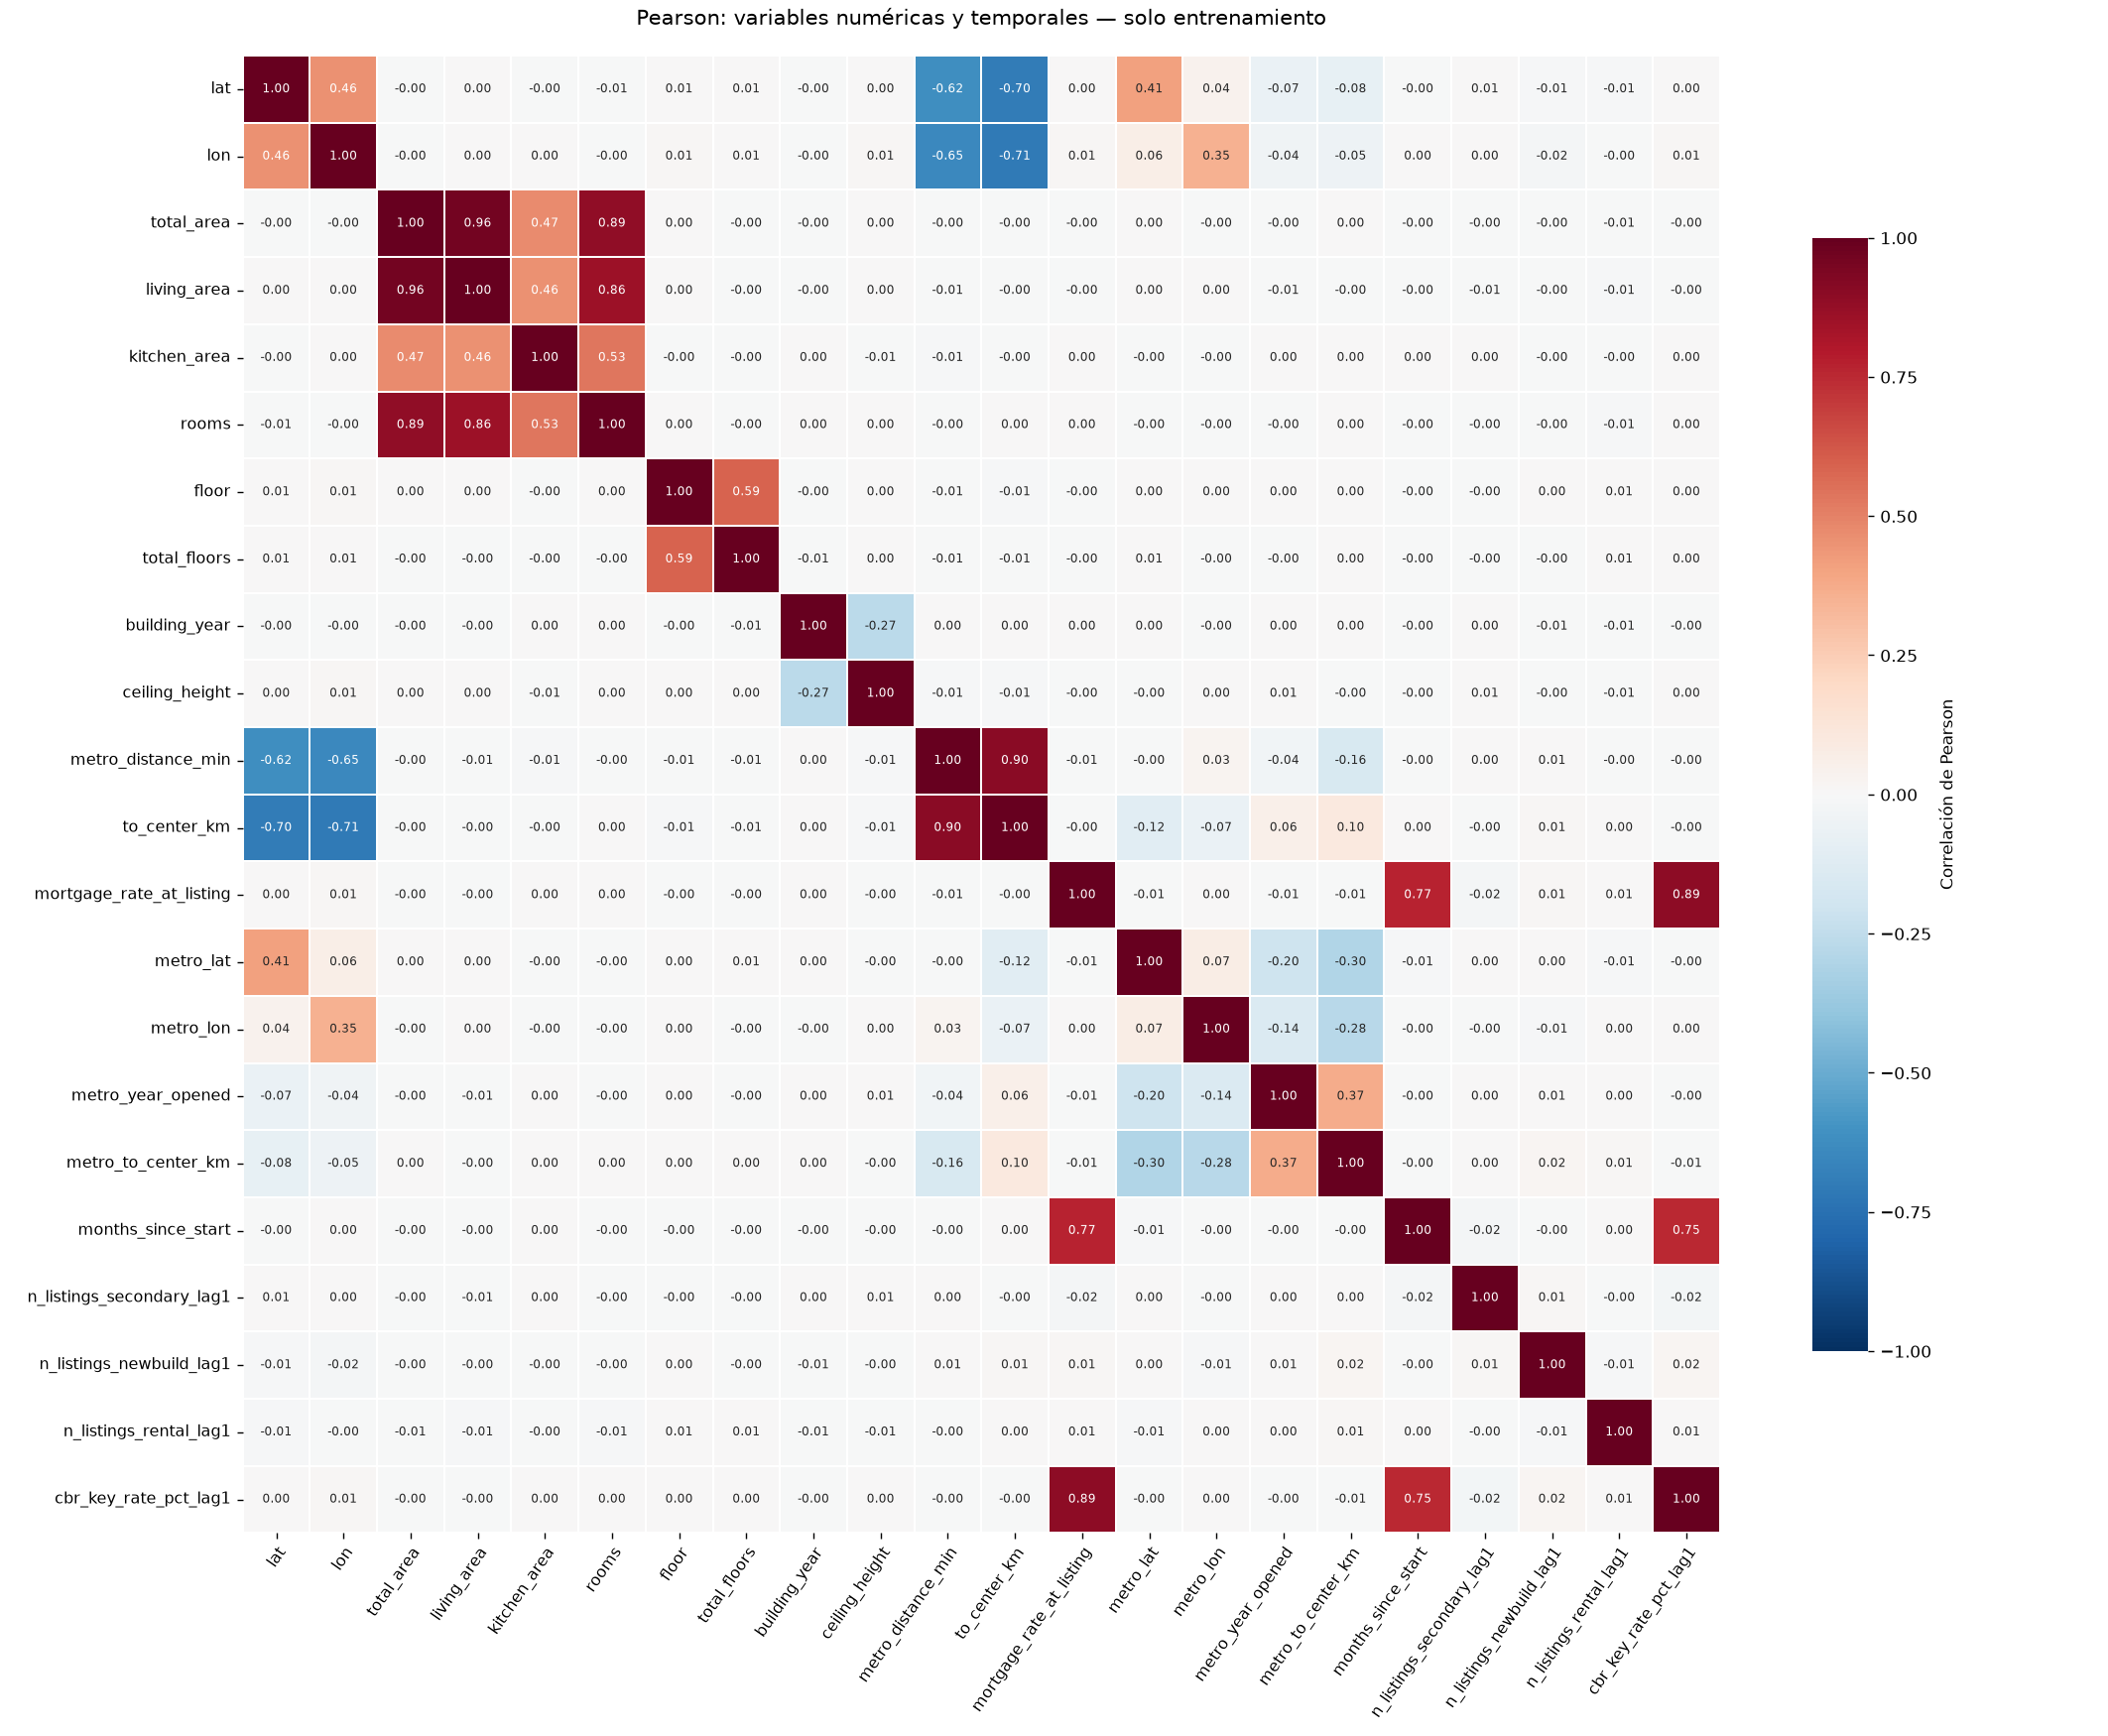

In [14]:
# Pearson completo, incluidos One-Hot y variables binarias.
pearson_completo = X_diagnostico.corr(method="pearson")
triangulo_superior = np.triu(np.ones(pearson_completo.shape, dtype=bool), k=1)
correlaciones_pares = pearson_completo.where(triangulo_superior).stack()
pares_pearson_altos = correlaciones_pares.loc[correlaciones_pares.abs() >= 0.80].rename("r").reset_index()
pares_pearson_altos.columns = ["variable_1", "variable_2", "r"]
pares_pearson_altos["abs_r"] = pares_pearson_altos["r"].abs()
pares_pearson_altos = pares_pearson_altos.sort_values("abs_r", ascending=False, kind="stable").reset_index(drop=True)
print("Matriz de Pearson completa disponible en pearson_completo:", pearson_completo.shape)
print("Pares únicos con |r| ≥ 0,80:", len(pares_pearson_altos))
print(pares_pearson_altos[["variable_1", "variable_2", "r"]].to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# Heatmap acotado a magnitudes numéricas originales y transformaciones temporales.
import matplotlib.pyplot as plt
import seaborn as sns
columnas_heatmap = variables_numericas_conservadas + ["months_since_start"] + columnas_lag1
assert len(columnas_heatmap) == len(set(columnas_heatmap))
fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(
    pearson_completo.loc[columnas_heatmap, columnas_heatmap],
    vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f",
    annot_kws={"size": 7}, square=True, linewidths=0.25,
    cbar_kws={"label": "Correlación de Pearson", "shrink": 0.75}, ax=ax,
)
ax.set_title("Pearson: variables numéricas y temporales — solo entrenamiento", pad=18)
ax.tick_params(axis="both", labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=55, ha="right", rotation_mode="anchor")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()
plt.close(fig)

In [15]:
# Constantes y columnas idénticas, sin utilizar la matriz de prueba.
columnas_constantes = X_diagnostico.columns[X_diagnostico.nunique(dropna=False).le(1)].tolist()
candidatas_identicas = X_diagnostico.T.duplicated(keep=False)
columnas_identicas = X_diagnostico.columns[candidatas_identicas].tolist()
pares_identicos = [
    (columna, otra)
    for posicion, columna in enumerate(columnas_identicas)
    for otra in columnas_identicas[posicion + 1:]
    if np.array_equal(X_diagnostico[columna].to_numpy(), X_diagnostico[otra].to_numpy())
]
print("Columnas constantes o con varianza cero:", columnas_constantes)
print("Pares de columnas idénticas:", pares_identicos)

# Rango con intercepto en una copia auxiliar, manteniendo las unidades originales.
matriz_diseno_diagnostico = np.column_stack([
    np.ones(len(X_diagnostico)), X_diagnostico.to_numpy(dtype=float)
])
valores_singulares = svdvals(matriz_diseno_diagnostico)
tolerancia_rango = max(matriz_diseno_diagnostico.shape) * np.finfo(float).eps * valores_singulares[0]
rango_diseno = int((valores_singulares > tolerancia_rango).sum())
columnas_diseno = matriz_diseno_diagnostico.shape[1]
print(f"Rango con intercepto: {rango_diseno}/{columnas_diseno}")
print(f"Tolerancia SVD: {tolerancia_rango:.12g}")
print(f"Menor valor singular: {valores_singulares[-1]:.12g}")
assert not columnas_constantes and not pares_identicos
assert rango_diseno == columnas_diseno, "Revisar dependencias estructurales antes de calcular VIF."
columnas_excluidas_dependencia_exacta = []
print("No se encontraron dependencias exactas a la tolerancia indicada; exclusiones necesarias: ninguna.")
print("Se conservan las 184 columnas y las mismas matrices de entrenamiento y prueba.")
del matriz_diseno_diagnostico

Columnas constantes o con varianza cero: []
Pares de columnas idénticas: []
Rango con intercepto: 185/185
Tolerancia SVD: 4.9858930878e-06
Menor valor singular: 0.0370141393502
No se encontraron dependencias exactas a la tolerancia indicada; exclusiones necesarias: ninguna.
Se conservan las 184 columnas y las mismas matrices de entrenamiento y prueba.


In [16]:
# VIF con intercepto: diagonal de (Z'Z)^(-1) multiplicada por las sumas de cuadrados.
# Z es una copia centrada solo para el cálculo numérico; X_train conserva sus unidades.
Z_vif = X_diagnostico.to_numpy(dtype=float)
Z_vif = Z_vif - Z_vif.mean(axis=0)
sumas_cuadrados_vif = np.sum(Z_vif ** 2, axis=0)
Q_vif, R_vif = qr(Z_vif, mode="economic")
R_inversa_vif = solve_triangular(R_vif, np.eye(R_vif.shape[0]), lower=False)
valores_vif = sumas_cuadrados_vif * np.sum(R_inversa_vif ** 2, axis=1)
assert not np.isnan(valores_vif).any()
assert (valores_vif >= 1 - 1e-8).all()
vif_completo = pd.DataFrame({"variable": X_diagnostico.columns, "VIF": valores_vif})
vif_completo = vif_completo.sort_values("VIF", ascending=False, kind="stable").reset_index(drop=True)
n_vif_mayor_5 = int(vif_completo["VIF"].gt(5).sum())
n_vif_mayor_10 = int(vif_completo["VIF"].gt(10).sum())
variables_vif_infinito = vif_completo.loc[np.isinf(vif_completo["VIF"]), "variable"].tolist()
print("Variables analizadas:", len(vif_completo))
print("Variables con VIF > 5:", n_vif_mayor_5)
print("Variables con VIF > 10:", n_vif_mayor_10)
print("Variables con VIF infinito:", variables_vif_infinito)
print("\nLas 20 variables con mayor VIF:")
print(vif_completo.head(20).to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\nResultado completo disponible en vif_completo (sin constante):")
print(vif_completo.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
del Q_vif, R_vif, R_inversa_vif, Z_vif

Variables analizadas: 184
Variables con VIF > 5: 41
Variables con VIF > 10: 17
Variables con VIF infinito: []

Las 20 variables con mayor VIF:
                        variable        VIF
                             lat 145.162752
                    to_center_km 107.037972
                             lon 102.322436
                district_Kievsky  38.053023
      district_Novofyodorovskoye  34.348793
             district_Rogovskoye  32.604511
           district_Voronovskoye  30.554808
           district_Klyonovskoye  28.713186
district_Mikhaylovo-Yartsevskoye  20.641841
          district_Pervomayskoye  17.721180
          district_Shchapovskoye  17.694475
                      total_area  17.669178
      district_Krasnopakhorskoye  14.601222
                     living_area  14.069787
                district_Troitsk  11.828666
              metro_distance_min  10.885249
          district_Ryazanovskoye  10.353855
             district_Zelenograd   9.595847
         district_Mar

In [17]:
# Comparación de asociación entre pares y multicolinealidad conjunta.
max_abs_pearson = pearson_completo.where(~np.eye(len(pearson_completo), dtype=bool)).abs().max()
comparacion_pearson_vif = vif_completo.copy()
comparacion_pearson_vif["max_abs_r"] = comparacion_pearson_vif["variable"].map(max_abs_pearson)
comparacion_pearson_vif["par_abs_r_ge_080"] = comparacion_pearson_vif["max_abs_r"].ge(0.80)
comparacion_pearson_vif["par_abs_r_ge_090"] = comparacion_pearson_vif["max_abs_r"].ge(0.90)
ambos_problemas = comparacion_pearson_vif.loc[
    comparacion_pearson_vif["VIF"].gt(10) & comparacion_pearson_vif["par_abs_r_ge_080"]
]
vif_alto_sin_par_alto = comparacion_pearson_vif.loc[
    comparacion_pearson_vif["VIF"].gt(10) & ~comparacion_pearson_vif["par_abs_r_ge_080"]
]
print("VIF > 10 y al menos un par con |r| ≥ 0,80:")
print(ambos_problemas[["variable", "VIF", "max_abs_r"]].to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\nVIF > 10 sin ningún par con |r| ≥ 0,80:")
print(vif_alto_sin_par_alto[["variable", "VIF", "max_abs_r"]].to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# Resumen de los grupos solicitados: cifras observadas, sin presumir problemas.
grupos_revision = {
    "Superficies": ["total_area", "living_area", "kitchen_area"],
    "Pisos": ["floor", "total_floors"],
    "Ubicación y distancias": ["lat", "lon", "to_center_km", "metro_distance_min"],
    "Estaciones de metro": ["metro_lat", "metro_lon", "metro_year_opened", "metro_to_center_km"],
    "Tasas": ["mortgage_rate_at_listing", "cbr_key_rate_pct_lag1"],
    "Actividad lag1": ["n_listings_secondary_lag1", "n_listings_newbuild_lag1", "n_listings_rental_lag1"],
    "Tendencia y ausencia de lag1": ["months_since_start", "lag1_unavailable"],
    "One-Hot": nombres_ohe,
}
print("\nRevisión por grupos (detalle por variable en comparacion_pearson_vif):")
for grupo, columnas in grupos_revision.items():
    detalle = comparacion_pearson_vif.set_index("variable").loc[columnas]
    print(f"{grupo}: n={len(detalle)}, VIF > 10={int(detalle['VIF'].gt(10).sum())}, "
          f"VIF máximo={detalle['VIF'].max():.3f}, mayor |r| con otra predictora={detalle['max_abs_r'].max():.3f}")

# El diagnóstico no cambia matrices ni añade una constante.
pd.testing.assert_frame_equal(X_train, X_diagnostico)
assert X_train.columns.equals(X_test.columns)
assert X_train.shape == (40_000, 184) and X_test.shape == (10_000, 184)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert columnas_excluidas_dependencia_exacta == []
print("\nDiagnóstico finalizado sin exclusiones; matrices alineadas y sin modificaciones.")

VIF > 10 y al menos un par con |r| ≥ 0,80:
          variable        VIF  max_abs_r
      to_center_km 107.037972   0.900975
        total_area  17.669178   0.963635
       living_area  14.069787   0.963635
metro_distance_min  10.885249   0.900975

VIF > 10 sin ningún par con |r| ≥ 0,80:
                        variable        VIF  max_abs_r
                             lat 145.162752   0.702276
                             lon 102.322436   0.709389
                district_Kievsky  38.053023   0.387741
      district_Novofyodorovskoye  34.348793   0.331136
             district_Rogovskoye  32.604511   0.324706
           district_Voronovskoye  30.554808   0.297740
           district_Klyonovskoye  28.713186   0.281841
district_Mikhaylovo-Yartsevskoye  20.641841   0.221288
          district_Pervomayskoye  17.721180   0.220766
          district_Shchapovskoye  17.694475   0.210952
      district_Krasnopakhorskoye  14.601222   0.168760
                district_Troitsk  11.828666   0.142

#### Resumen del análisis de multicolinealidad

**Correlación de Pearson**

Se encontraron **5 pares únicos con |r| ≥ 0,80** entre los 184 predictores de entrenamiento:

- `total_area`–`living_area`: r = 0.9636.
- `metro_distance_min`–`to_center_km`: r = 0.9010.
- `mortgage_rate_at_listing`–`cbr_key_rate_pct_lag1`: r = 0.8935.
- `total_area`–`rooms`: r = 0.8882.
- `living_area`–`rooms`: r = 0.8571.

Las asociaciones más intensas corresponden a superficies y a tiempo de acceso al metro frente a distancia al centro. Las tasas presentan asociación fuerte, mientras que ninguna pareja de recuentos lag1 alcanza el umbral de 0,80. El diagnóstico completo también incorpora binarias y One-Hot; el heatmap muestra únicamente 22 variables numéricas para facilitar la lectura.

**Factor de Inflación de la Varianza**

De 184 variables, **41 tienen VIF > 5** y **17 tienen VIF > 10**; no hay VIF infinitos. Los cinco valores más altos son `lat` (145.16), `to_center_km` (107.04), `lon` (102.32), `district_Kievsky` (38.05), `district_Novofyodorovskoye` (34.35). Las 20 primeras y la lista completa se muestran arriba; `vif_completo` conserva todos los resultados, incluidos los One-Hot.

13 variables presentan VIF > 10 sin ninguna correlación individual con |r| ≥ 0,80: `lat`, `lon`, `district_Kievsky`, `district_Novofyodorovskoye`, `district_Rogovskoye`, `district_Voronovskoye`, `district_Klyonovskoye`, `district_Mikhaylovo-Yartsevskoye`, `district_Pervomayskoye`, `district_Shchapovskoye`, `district_Krasnopakhorskoye`, `district_Troitsk`, `district_Ryazanovskoye`. Este resultado muestra dependencias conjuntas entre varias predictoras que Pearson por pares no detecta. Las coincidencias entre ambos criterios y el detalle por variable quedan en `comparacion_pearson_vif`.

**Dependencias lineales exactas**

No se encontraron columnas constantes, columnas idénticas ni dependencias exactas a la tolerancia SVD **4.99e-06**. La matriz auxiliar con intercepto tiene **rango 185/185**, con menor valor singular 0.037014; por tanto, tiene rango completo. No se excluye ninguna columna y no se agrega una constante a `X_train` o `X_test`.

**Conclusión**

El diseño permite identificar los coeficientes de un futuro OLS, aunque varios pueden ser inestables por multicolinealidad elevada. Se mantienen todas las variables, incluidas las superficies, las características de ubicación y metro, las tasas y las columnas One-Hot con VIF alto, para construir posteriormente el modelo completo de referencia. Podrán evaluarse en una etapa futura de selección de variables; aquí no se aplica selección ni entrenamiento. Las matrices permanecen sin cambios, con 40.000 y 10.000 observaciones y 184 predictores alineados. Las decisiones se basaron exclusivamente en entrenamiento.

### Configuración de MLflow remoto mediante DagsHub

Se usa el mismo entorno virtual `.venv` del proyecto. La celda verifica el intérprete del kernel y las dependencias `mlflow`, `dagshub` y `python-dotenv`; si el kernel es incorrecto, debe seleccionarse el Python de `.venv` antes de continuar. No se crea otro entorno ni se instalan paquetes al volver a ejecutar el notebook.

Se localiza el `.env` existente en la raíz mediante rutas relativas a la estructura del proyecto, se comprueba su exclusión de Git y se carga `DAGSHUB_USER_TOKEN` sin mostrarlo. `dagshub.init()` configura la autenticación y el seguimiento para `matiasgastonlonghino/MOSCOW_IDA`, con `mlflow=True`, `dvc=False` y `patch_mlflow=False`: los errores se propagan. Se verifica previamente que el repositorio exista y se fija explícitamente la Tracking URI para reemplazar configuraciones anteriores. Esta etapa solo prueba seguimiento remoto; no entrena el OLS ni altera matrices.

In [18]:
from pathlib import Path
import os
import sys
import subprocess
from importlib.metadata import version

raiz_proyecto = next(
    (base for base in [Path.cwd(), *Path.cwd().parents]
     if (base / ".env").is_file() and (base / "Data").is_dir() and (base / "Ventas").is_dir()),
    None,
)
assert raiz_proyecto is not None, "No se encontró el .env existente en la raíz del proyecto."
assert Path(sys.prefix).resolve() == (raiz_proyecto / ".venv").resolve(), (
    "Seleccionar el kernel de .venv del proyecto antes de continuar."
)
versiones_tracking = {nombre: version(nombre) for nombre in ["mlflow", "dagshub", "python-dotenv"]}
print("Kernel verificado: entorno virtual .venv del proyecto.")
print("Dependencias disponibles:", versiones_tracking)

archivo_env = raiz_proyecto / ".env"
resultado_ignore = subprocess.run(
    ["git", "check-ignore", "-q", ".env"], cwd=raiz_proyecto, capture_output=True,
)
assert resultado_ignore.returncode == 0, ".env debe estar excluido de Git antes de continuar."
resultado_tracked = subprocess.run(
    ["git", "ls-files", "--error-unmatch", ".env"], cwd=raiz_proyecto, capture_output=True,
)
assert resultado_tracked.returncode != 0, ".env no debe estar incorporado al repositorio."

from dotenv import load_dotenv
load_dotenv(dotenv_path=archivo_env, override=True)
assert os.environ.get("DAGSHUB_USER_TOKEN", "").strip(), "Falta DAGSHUB_USER_TOKEN en el .env existente."
print("Credencial cargada desde .env; archivo ignorado y no versionado en Git.")

# Importar DagsHub después de cargar su variable de autenticación.
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import dagshub
import mlflow
from dagshub.common.api import RepoAPI
from mlflow.tracking import MlflowClient

tracking_uri_dagshub = "https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow"
assert mlflow.active_run() is None, "Finalizar el Run activo antes de configurar otro destino."
# La comprobación previa impide que init intente crear un repositorio inexistente.
RepoAPI("matiasgastonlonghino/MOSCOW_IDA", host="https://dagshub.com").get_repo_info()
dagshub.init(
    repo_owner="matiasgastonlonghino", repo_name="MOSCOW_IDA",
    mlflow=True, dvc=False, patch_mlflow=False,
)
mlflow.set_tracking_uri(tracking_uri_dagshub)
assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
cliente_mlflow_prueba = MlflowClient(tracking_uri=tracking_uri_dagshub)
# Consulta autenticada al servidor; los permisos de escritura se confirman con ambos Runs.
experimento_prueba_previo = cliente_mlflow_prueba.get_experiment_by_name("Test_Conexion_DagsHub")
print("Conexión autenticada al servidor remoto verificada.")
print("Tracking URI activa:", mlflow.get_tracking_uri())

Kernel verificado: entorno virtual .venv del proyecto.
Dependencias disponibles: {'mlflow': '3.17.1', 'dagshub': '0.7.3', 'python-dotenv': '1.2.4'}
Credencial cargada desde .env; archivo ignorado y no versionado en Git.
Accessing as matiasgastonlonghino
Initialized MLflow to track repo "matiasgastonlonghino/MOSCOW_IDA"
Repository matiasgastonlonghino/MOSCOW_IDA initialized!
Conexión autenticada al servidor remoto verificada.
Tracking URI activa: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow


### Prueba de conexión y registro remoto

Se crea o reutiliza exclusivamente `Test_Conexion_DagsHub`. Cada ejecución de la celda siguiente crea dos Runs independientes: `Prueba_Remota_01` y `Prueba_Remota_02`, con parámetros y métricas ficticios. No se reutilizan Run ID ni se sobrescriben ejecuciones anteriores. Cada contexto finaliza el Run correctamente o lo marca como fallido si ocurre un error.

Se registra un texto de prueba por Run sin credenciales ni información personal. La verificación consulta de nuevo el servidor, valida los Run ID, estados, parámetros y métricas, y descarga temporalmente cada artefacto para comprobar su contenido. No se crean archivos permanentes en el proyecto ni se utiliza todavía `Ventas_Propiedades_Usadas`. Los valores de MAE y R² son datos ficticios para comprobar la comparación en la interfaz web; no son resultados de un modelo.

In [19]:
assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
assert mlflow.active_run() is None, "Hay un Run activo; finalizarlo antes de iniciar las pruebas."
experimento_prueba = mlflow.set_experiment("Test_Conexion_DagsHub")
assert experimento_prueba.lifecycle_stage == "active"

parametros_prueba = {
    "modelo": "OLS_TEST", "dataset": "MOSCOW_IDA", "tipo_ejecucion": "prueba_conexion",
}
especificaciones_prueba = [
    {"nombre": "Prueba_Remota_01", "mae_test": 2500000, "r2_test": 0.75,
     "artefacto": "prueba_remota_01.txt",
     "texto": "Primera prueba de conexión con DagsHub. Datos ficticios; no se entrenó ningún modelo.\n"},
    {"nombre": "Prueba_Remota_02", "mae_test": 2000000, "r2_test": 0.82,
     "artefacto": "prueba_remota_02.txt",
     "texto": "Segunda prueba de conexión con DagsHub. Datos ficticios; no se entrenó ningún modelo.\n"},
]
runs_prueba_creados = []
for prueba in especificaciones_prueba:
    with mlflow.start_run(experiment_id=experimento_prueba.experiment_id, run_name=prueba["nombre"]) as run_prueba:
        mlflow.log_params(parametros_prueba)
        mlflow.log_metrics({"mae_test": prueba["mae_test"], "r2_test": prueba["r2_test"]})
        mlflow.log_text(prueba["texto"], artifact_file=prueba["artefacto"])
        runs_prueba_creados.append({**prueba, "run_id": run_prueba.info.run_id})
assert mlflow.active_run() is None
print("Dos Runs de prueba enviados; se verificará su persistencia en el servidor remoto.")

2026/10/17 13:34:44 INFO mlflow.tracking.fluent: Experiment with name 'Test_Conexion_DagsHub' does not exist. Creating a new experiment.
🏃 View run Prueba_Remota_01 at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/0/runs/37ade2ddf8b747d883a4960a9574d92a
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/0
🏃 View run Prueba_Remota_02 at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/0/runs/64be045c36934dd0a46a8c7cd4aa1aa2
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/0
Dos Runs de prueba enviados; se verificará su persistencia en el servidor remoto.


In [20]:
import math
from tempfile import TemporaryDirectory
import pandas as pd

assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
experimento_verificado = cliente_mlflow_prueba.get_experiment_by_name("Test_Conexion_DagsHub")
assert experimento_verificado is not None
assert experimento_verificado.experiment_id == experimento_prueba.experiment_id
assert len(runs_prueba_creados) == 2
assert len({prueba["run_id"] for prueba in runs_prueba_creados}) == 2
verificacion_runs = []
for prueba in runs_prueba_creados:
    run_remoto = cliente_mlflow_prueba.get_run(prueba["run_id"])
    assert run_remoto.info.experiment_id == experimento_verificado.experiment_id
    assert run_remoto.info.status == "FINISHED"
    assert run_remoto.data.tags["mlflow.runName"] == prueba["nombre"]
    for clave, valor in parametros_prueba.items():
        assert run_remoto.data.params[clave] == valor
    for metrica in ["mae_test", "r2_test"]:
        assert math.isclose(run_remoto.data.metrics[metrica], prueba[metrica], rel_tol=0, abs_tol=1e-12)
    artefactos_remotos = cliente_mlflow_prueba.list_artifacts(prueba["run_id"])
    assert any(artefacto.path == prueba["artefacto"] and not artefacto.is_dir for artefacto in artefactos_remotos)
    with TemporaryDirectory(prefix="dagshub_prueba_") as carpeta_temporal:
        archivo_recuperado = cliente_mlflow_prueba.download_artifacts(
            prueba["run_id"], prueba["artefacto"], dst_path=carpeta_temporal,
        )
        assert Path(archivo_recuperado).read_text(encoding="utf-8") == prueba["texto"]
    verificacion_runs.append({
        "Run": prueba["nombre"], "Run ID": run_remoto.info.run_id,
        "Estado": run_remoto.info.status,
        "mae_test": run_remoto.data.metrics["mae_test"],
        "r2_test": run_remoto.data.metrics["r2_test"], "Artefacto recuperado": True,
    })

resultado_pruebas_dagshub = pd.DataFrame(verificacion_runs)
print(resultado_pruebas_dagshub.to_string(index=False))
print("Registro remoto, permisos de escritura y recuperación de ambos artefactos: verificados.")
print("Experimento:", tracking_uri_dagshub + "/#/experiments/" + experimento_verificado.experiment_id)
for prueba in runs_prueba_creados:
    print(prueba["nombre"] + ": " + tracking_uri_dagshub + "/#/experiments/"
          + experimento_verificado.experiment_id + "/runs/" + prueba["run_id"])
print("Para comparar en la interfaz web: seleccionar los dos Runs del experimento y elegir Compare.")

             Run                           Run ID   Estado  mae_test  r2_test  Artefacto recuperado
Prueba_Remota_01 37ade2ddf8b747d883a4960a9574d92a FINISHED 2500000.0     0.75                  True
Prueba_Remota_02 64be045c36934dd0a46a8c7cd4aa1aa2 FINISHED 2000000.0     0.82                  True
Registro remoto, permisos de escritura y recuperación de ambos artefactos: verificados.
Experimento: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/0
Prueba_Remota_01: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/0/runs/37ade2ddf8b747d883a4960a9574d92a
Prueba_Remota_02: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/0/runs/64be045c36934dd0a46a8c7cd4aa1aa2
Para comparar en la interfaz web: seleccionar los dos Runs del experimento y elegir Compare.


### Entrenamiento del modelo OLS — Iteración 1: Baseline

Se entrena un modelo OLS utilizando todas las variables predictoras válidas resultantes del preprocesamiento. Su rendimiento será utilizado como referencia para comparar futuras iteraciones con distintos métodos de selección de variables y regularización.

In [21]:
# Verificación de las matrices
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, r2_score

assert X_train.columns.equals(X_test.columns)
assert "price_rub" not in X_train.columns
assert set(vif_completo["variable"]) == set(X_train.columns)
pd.testing.assert_frame_equal(X_train, X_diagnostico)
assert rango_diseno == X_train.shape[1] + 1
for matriz, objetivo in [(X_train, y_train), (X_test, y_test)]:
    assert matriz.columns.is_unique and matriz.index.equals(objetivo.index)
    assert len(matriz) == len(objetivo)
    assert all(is_numeric_dtype(tipo) and not is_bool_dtype(tipo) for tipo in matriz.dtypes)
    assert not matriz.isna().any().any() and objetivo.notna().all()
    assert np.isfinite(matriz.to_numpy(dtype=float)).all()
    assert np.isfinite(objetivo.to_numpy(dtype=float)).all()
assert X_train.shape == (40_000, 184) and X_test.shape == (10_000, 184)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Predictores:", X_train.shape[1], "| rango con intercepto ya validado:", rango_diseno)

X_train: (40000, 184) | y_train: (40000,)
X_test: (10000, 184) | y_test: (10000,)
Predictores: 184 | rango con intercepto ya validado: 185


In [22]:
# Verificación de MLflow y DagsHub
import mlflow.statsmodels
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
assert tracking_uri_dagshub == "https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow"
assert mlflow.active_run() is None
cliente_baseline = MlflowClient(tracking_uri=tracking_uri_dagshub)
cliente_baseline.search_experiments(max_results=1)
print("Conexión remota verificada:", mlflow.get_tracking_uri())

Conexión remota verificada: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow


In [23]:
# Entrenamiento OLS completo
X_train_ols = sm.add_constant(X_train.astype(float), has_constant="raise")
X_test_ols = sm.add_constant(X_test.astype(float), has_constant="raise")
assert X_train_ols.columns.equals(X_test_ols.columns)
assert X_train_ols.shape[1] == X_train.shape[1] + 1 == rango_diseno
modelo_ols_baseline = sm.OLS(y_train, X_train_ols, missing="raise").fit()
assert int(modelo_ols_baseline.df_model) == X_train.shape[1]
print(modelo_ols_baseline.summary().as_text())

                            OLS Regression Results                            
Dep. Variable:              price_rub   R-squared:                       0.874
Model:                            OLS   Adj. R-squared:                  0.874
Method:                 Least Squares   F-statistic:                     1504.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:36:12   Log-Likelihood:            -6.5295e+05
No. Observations:               40000   AIC:                         1.306e+06
Df Residuals:                   39815   BIC:                         1.308e+06
Df Model:                         184                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

In [24]:
# Predicciones y métricas
pred_train_baseline = modelo_ols_baseline.predict(X_train_ols)
pred_test_baseline = modelo_ols_baseline.predict(X_test_ols)
assert pred_train_baseline.index.equals(y_train.index)
assert pred_test_baseline.index.equals(y_test.index)
assert np.isfinite(pred_train_baseline).all() and np.isfinite(pred_test_baseline).all()
metricas_baseline = {
    "r2_train": float(r2_score(y_train, pred_train_baseline)),
    "r2_test": float(r2_score(y_test, pred_test_baseline)),
    "r2_adjusted_train": float(modelo_ols_baseline.rsquared_adj),
    "mae_train": float(mean_absolute_error(y_train, pred_train_baseline)),
    "mae_test": float(mean_absolute_error(y_test, pred_test_baseline)),
    "aic": float(modelo_ols_baseline.aic), "bic": float(modelo_ols_baseline.bic),
    "mss_train": float(modelo_ols_baseline.ess), "rss_train": float(modelo_ols_baseline.ssr),
    "mse_model": float(modelo_ols_baseline.mse_model),
}
comparacion_baseline = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "MAE (RUB)": [metricas_baseline["mae_train"], metricas_baseline["mae_test"]],
    "R2": [metricas_baseline["r2_train"], metricas_baseline["r2_test"]],
})
print(comparacion_baseline.to_string(index=False, float_format=lambda v: f"{v:,.6f}"))
print("\nAjuste estadístico de entrenamiento:")
print(pd.Series({k: v for k, v in metricas_baseline.items() if k not in ["r2_train", "r2_test", "mae_train", "mae_test"]}).to_string())
print("Métrica principal: mae_test, expresada en rublos.")

     Conjunto        MAE (RUB)       R2
Entrenamiento 1,952,062.282363 0.874236
       Prueba 2,759,079.296245 0.840639

Ajuste estadístico de entrenamiento:
r2_adjusted_train    8.736552e-01
aic                  1.306277e+06
bic                  1.307867e+06
mss_train            2.456750e+18
rss_train            3.534167e+17
mse_model            1.335190e+16
Métrica principal: mae_test, expresada en rublos.


In [25]:
# Coeficientes y estadísticos
tabla_coeficientes_baseline = pd.DataFrame({
    "variable": modelo_ols_baseline.params.index,
    "coeficiente": modelo_ols_baseline.params.to_numpy(),
    "std_err": modelo_ols_baseline.bse.to_numpy(),
    "t_value": modelo_ols_baseline.tvalues.to_numpy(),
    "p_value": modelo_ols_baseline.pvalues.to_numpy(),
    "significativo_005": modelo_ols_baseline.pvalues.to_numpy() < 0.05,
})
assert len(tabla_coeficientes_baseline) == X_train_ols.shape[1]
print(tabla_coeficientes_baseline.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
print("\nVIF previo reutilizado, sin recalcular:")
print(vif_completo.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

                               variable  coeficiente     std_err    t_value      p_value  significativo_005
                                  const  5.08715e+07  8.0453e+07   0.632313     0.527186              False
                                    lat -2.52144e+06 1.24566e+06   -2.02418    0.0429578               True
                                    lon      -136554      838412  -0.162872      0.87062              False
                             total_area       192086     3621.26    53.0442            0               True
                            living_area      767.941     4989.85     0.1539     0.877689              False
                           kitchen_area      16462.2     6181.92    2.66296   0.00774888               True
                                  rooms     -52233.6     33074.3   -1.57928      0.11428              False
                                  floor        10353     3342.97    3.09694   0.00195667               True
                           t

In [26]:
# Diagnóstico de residuos
from statsmodels.stats.stattools import omni_normtest, jarque_bera

omnibus_baseline, omnibus_pvalue_baseline = omni_normtest(modelo_ols_baseline.resid)
jb_baseline, jb_pvalue_baseline, skew_baseline, kurtosis_baseline = jarque_bera(modelo_ols_baseline.resid)
diagnostico_residuos_baseline = {
    "omnibus": float(omnibus_baseline), "omnibus_pvalue": float(omnibus_pvalue_baseline),
    "skew": float(skew_baseline), "kurtosis": float(kurtosis_baseline),
    "jarque_bera": float(jb_baseline), "jarque_bera_pvalue": float(jb_pvalue_baseline),
}
metricas_baseline.update(diagnostico_residuos_baseline)
assert all(np.isfinite(v) for v in metricas_baseline.values())
print(pd.Series(diagnostico_residuos_baseline).to_string())

omnibus                21308.769010
omnibus_pvalue             0.000000
skew                       2.030233
kurtosis                  21.080479
jarque_bera           572318.499710
jarque_bera_pvalue         0.000000


In [27]:
# Registro del baseline en MLflow
from copy import deepcopy
from importlib.metadata import version
import platform


def registrar_experimento(modelo, metricas, informacion, artefactos, registrador_modelo, opciones_modelo):
    assert mlflow.active_run() is None, "Finalizar el Run activo antes de registrar otro."
    experimento = mlflow.set_experiment(informacion["experimento"])
    with mlflow.start_run(experiment_id=experimento.experiment_id, run_name=informacion["run"]) as run:
        mlflow.log_params(informacion["parametros"])
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})
        for ruta, texto in artefactos["textos"].items():
            mlflow.log_text(texto, artifact_file=ruta)
        for ruta, contenido in artefactos["json"].items():
            mlflow.log_dict(contenido, artifact_file=ruta)
        info_modelo = registrador_modelo(deepcopy(modelo), name="modelo", **opciones_modelo)
        mlflow.log_dict({"model_uri": info_modelo.model_uri, "model_id": info_modelo.model_id}, "modelo_uri.json")
        registro = {
            "run_id": run.info.run_id, "experiment_id": experimento.experiment_id,
            "model_uri": info_modelo.model_uri, "model_id": info_modelo.model_id,
        }
    print("Run finalizado:", registro["run_id"])
    return registro


versiones_baseline = {nombre: version(nombre) for nombre in ["statsmodels", "numpy", "pandas", "scipy", "scikit-learn", "mlflow", "dagshub"]}
parametros_baseline = {
    "nombre_modelo": "OLS_Completo_Baseline", "tipo_modelo": "statsmodels.OLS", "metodo": "OLS",
    "target": "price_rub", "n_predictoras": X_train.shape[1],
    "n_train": len(X_train), "n_test": len(X_test), "proporcion_train_test": "80/20",
    "division": "cronologica_date_posted", "intercepto": True,
    "train_inicio": X_train_base["date_posted"].min().date().isoformat(),
    "train_fin": X_train_base["date_posted"].max().date().isoformat(),
    "test_inicio": X_test_base["date_posted"].min().date().isoformat(),
    "test_fin": X_test_base["date_posted"].max().date().isoformat(),
    "n_exclusiones_dependencias_exactas": len(columnas_excluidas_dependencia_exacta),
    "python_version": platform.python_version(),
    **{f"version_{nombre}": valor for nombre, valor in versiones_baseline.items()},
}
notebook_actual_baseline = raiz_proyecto / "Ventas" / "Propiedades_Usadas" / "Modelo_OLS.ipynb"
import json
contenido_notebook_baseline = json.loads(notebook_actual_baseline.read_text(encoding="utf-8"))
resumen_transformaciones_baseline = next(
    "".join(celda["source"]) for celda in contenido_notebook_baseline["cells"]
    if "".join(celda["source"]).startswith("### Resumen de preparación de variables para OLS")
)
assert pearson_completo.columns.equals(X_train.columns)
artefactos_baseline = {
    "textos": {
        "resumen_ols.txt": modelo_ols_baseline.summary().as_text(),
        "coeficientes.csv": tabla_coeficientes_baseline.to_csv(index=False, lineterminator="\n"),
        "vif.csv": vif_completo.to_csv(index=False, lineterminator="\n"),
        "pearson_completo.csv": pearson_completo.rename_axis("variable").reset_index().to_csv(index=False, lineterminator="\n"),
        "pearson_pares_altos.csv": pares_pearson_altos.to_csv(index=False, lineterminator="\n"),
        "transformaciones.md": resumen_transformaciones_baseline,
    },
    "json": {
        "variables_predictoras.json": {"predictoras": X_train.columns.tolist(), "columnas_diseno": X_train_ols.columns.tolist()},
        "preprocesamiento.json": {
            "medias_entrenamiento": medias_imputacion.to_dict(),
            "medianas_lag1_entrenamiento": medianas_lag1.to_dict(),
            "exclusiones": columnas_excluidas + ["date_posted", "year_month"],
            "categorias_ohe": {col: cats.tolist() for col, cats in zip(columnas_ohe, codificador_ohe.categories_)},
            "referencias_ohe": {col: cats[int(idx)].item() if isinstance(cats[int(idx)], np.generic) else cats[int(idx)]
                                for col, cats, idx in zip(columnas_ohe, codificador_ohe.categories_, codificador_ohe.drop_idx_)},
            "fecha_base_tendencia": "2020-01", "matriz_requerida_para_predecir": "predictoras transformadas más const=1",
        },
    },
}
firma_baseline = infer_signature(X_train_ols.head(5), pred_train_baseline.head(5))
registro_baseline = registrar_experimento(
    modelo=modelo_ols_baseline, metricas=metricas_baseline,
    informacion={"experimento": "Ventas_Propiedades_Usadas", "run": "OLS_Completo_Baseline", "parametros": parametros_baseline},
    artefactos=artefactos_baseline, registrador_modelo=mlflow.statsmodels.log_model,
    opciones_modelo={
        "signature": firma_baseline, "remove_data": True,
        "pip_requirements": [f"{p}=={versiones_baseline[p]}" for p in ["statsmodels", "numpy", "pandas", "scipy", "mlflow"]],
    },
)

2026/10/17 21:36:13 INFO mlflow.tracking.fluent: Experiment with name 'Ventas_Propiedades_Usadas' does not exist. Creating a new experiment.
🏃 View run OLS_Completo_Baseline at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/20e7cf07a65447e69dceef2b73bd6098
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Run finalizado: 20e7cf07a65447e69dceef2b73bd6098


In [28]:
# Verificación del registro remoto
import math
from tempfile import TemporaryDirectory
from io import StringIO
import re

run_baseline_remoto = cliente_baseline.get_run(registro_baseline["run_id"])
assert run_baseline_remoto.info.status == "FINISHED"
assert run_baseline_remoto.data.tags["mlflow.runName"] == "OLS_Completo_Baseline"
experimento_baseline_remoto = cliente_baseline.get_experiment(registro_baseline["experiment_id"])
assert experimento_baseline_remoto.name == "Ventas_Propiedades_Usadas"
for nombre, valor in parametros_baseline.items():
    assert run_baseline_remoto.data.params[nombre] == str(valor)
for nombre, valor in metricas_baseline.items():
    assert math.isclose(run_baseline_remoto.data.metrics[nombre], valor, rel_tol=1e-10, abs_tol=1e-12)

rutas_remotas_baseline = {a.path for a in cliente_baseline.list_artifacts(registro_baseline["run_id"])}
assert set(artefactos_baseline["textos"]) | set(artefactos_baseline["json"]) | {"modelo_uri.json"} <= rutas_remotas_baseline
with TemporaryDirectory(prefix="verificacion_ols_") as carpeta_verificacion:
    for ruta, esperado in artefactos_baseline["textos"].items():
        descargado = cliente_baseline.download_artifacts(registro_baseline["run_id"], ruta, dst_path=carpeta_verificacion)
        if ruta.endswith(".csv"):
            pd.testing.assert_frame_equal(
                pd.read_csv(descargado), pd.read_csv(StringIO(esperado)),
                check_exact=False, rtol=1e-12, atol=1e-12,
            )
        else:
            texto_recuperado = Path(descargado).read_text(encoding="utf-8")
            if ruta == "resumen_ols.txt":
                # summary() incluye fecha y hora de renderizado; no son estadísticos del ajuste.
                patron_fecha_hora = r"[A-Za-z]{3},\s+\d{2}\s+[A-Za-z]{3}\s+\d{4}|\b\d{2}:\d{2}:\d{2}\b"
                assert re.sub(patron_fecha_hora, "[fecha/hora]", texto_recuperado) == re.sub(patron_fecha_hora, "[fecha/hora]", esperado), ruta
            else:
                assert texto_recuperado == esperado, ruta
    for ruta, esperado in artefactos_baseline["json"].items():
        descargado = cliente_baseline.download_artifacts(registro_baseline["run_id"], ruta, dst_path=carpeta_verificacion)
        assert json.loads(Path(descargado).read_text(encoding="utf-8")) == esperado
    modelo_baseline_recuperado = mlflow.statsmodels.load_model(registro_baseline["model_uri"], dst_path=carpeta_verificacion)
    assert modelo_baseline_recuperado.model.exog_names == X_train_ols.columns.tolist()
    pred_recuperadas_baseline = modelo_baseline_recuperado.predict(X_test_ols.head(20))
    np.testing.assert_allclose(pred_recuperadas_baseline, pred_test_baseline.head(20), rtol=1e-10, atol=1e-5)
modelo_remoto_baseline = cliente_baseline.get_logged_model(registro_baseline["model_id"])
assert modelo_remoto_baseline.source_run_id == registro_baseline["run_id"]
assert mlflow.active_run() is None
url_experimento_baseline = tracking_uri_dagshub + "/#/experiments/" + registro_baseline["experiment_id"]
url_run_baseline = url_experimento_baseline + "/runs/" + registro_baseline["run_id"]
print("Registro remoto FINISHED: parámetros, métricas, artefactos y modelo recuperable verificados.")
print("Predicciones del modelo recuperado: coinciden con las del modelo original.")
print("Run ID:", registro_baseline["run_id"])
print("Experimento:", url_experimento_baseline)
print("Run:", url_run_baseline)

Registro remoto FINISHED: parámetros, métricas, artefactos y modelo recuperable verificados.
Predicciones del modelo recuperado: coinciden con las del modelo original.
Run ID: 20e7cf07a65447e69dceef2b73bd6098
Experimento: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Run: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/20e7cf07a65447e69dceef2b73bd6098


### Forward Stepwise Selection — Iteración 2

Se implementa Forward Stepwise Selection para identificar automáticamente conjuntos de características mediante tres criterios: AIC, BIC y R² ajustado. Cada criterio selecciona características de manera independiente y posteriormente se entrena un modelo OLS con las características seleccionadas.

In [29]:
# Definición de grupos de características
grupos_forward = {}
inicio = 0
for posicion, original in enumerate(columnas_ohe):
    n_dummy = len(codificador_ohe.categories_[posicion]) - 1
    bloque = nombres_ohe[inicio:inicio + n_dummy]
    nombre = "date_posted" if original == "month_of_year" else original
    grupos_forward[nombre] = (["months_since_start"] if original == "month_of_year" else []) + bloque
    inicio += n_dummy
asignadas_forward = {col for bloque in grupos_forward.values() for col in bloque}
for columna in X_train.columns:
    if columna not in asignadas_forward:
        original = columna[:-5] if columna.endswith("_lag1") else columna
        assert original not in grupos_forward
        grupos_forward[original] = [columna]
columnas_agrupadas_forward = [col for bloque in grupos_forward.values() for col in bloque]
assert len(columnas_agrupadas_forward) == len(set(columnas_agrupadas_forward)) == X_train.shape[1]
assert set(columnas_agrupadas_forward) == set(X_train.columns)
assert grupos_forward["lag1_unavailable"] == ["lag1_unavailable"]
assert grupos_forward["date_posted"] == ["months_since_start"] + [c for c in nombres_ohe if c.startswith("month_of_year_")]
pd.testing.assert_frame_equal(X_train, X_diagnostico)
print("Características originales disponibles:", len(grupos_forward), "| columnas numéricas:", len(columnas_agrupadas_forward))
print(pd.DataFrame([{"caracteristica": k, "n_columnas": len(v), "columnas": ", ".join(v)} for k, v in grupos_forward.items()]).to_string(index=False))

Características originales disponibles: 30 | columnas numéricas: 184
          caracteristica  n_columnas                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

In [30]:
# Configuración de Forward Stepwise
from threadpoolctl import threadpool_limits
configuracion_forward = {
    "AIC": {"criterio": "aic", "mejora_minima": 2.0, "max_caracteristicas": 15, "run": "OLS_Forward_AIC"},
    "BIC": {"criterio": "bic", "mejora_minima": 2.0, "max_caracteristicas": 15, "run": "OLS_Forward_BIC"},
    "AdjR2": {"criterio": "adj_r2", "mejora_minima": 0.0001, "max_caracteristicas": 15, "run": "OLS_Forward_AdjR2"},
}
assert X_train.index.equals(y_train.index)
assert X_train.columns.equals(X_test.columns)
assert np.isfinite(X_train.to_numpy(dtype=float)).all() and np.isfinite(y_train.to_numpy(dtype=float)).all()
print(pd.DataFrame(configuracion_forward).T.to_string())

      criterio mejora_minima max_caracteristicas                run
AIC        aic           2.0                  15    OLS_Forward_AIC
BIC        bic           2.0                  15    OLS_Forward_BIC
AdjR2   adj_r2        0.0001                  15  OLS_Forward_AdjR2


In [31]:
# Implementación del algoritmo Forward Stepwise
def forward_stepwise(X, y, grupos, criterio, mejora_minima, max_caracteristicas=15, cache_ajustes=None):
    assert criterio in {"aic", "bic", "adj_r2"}
    assert mejora_minima >= 0 and 1 <= max_caracteristicas <= 15
    assert X.index.equals(y.index) and X.columns.is_unique
    columnas_grupos = [col for bloque in grupos.values() for col in bloque]
    assert len(columnas_grupos) == len(set(columnas_grupos)) and set(columnas_grupos) == set(X.columns)
    assert all(len(bloque) > 0 for bloque in grupos.values())
    diseno_completo = sm.add_constant(X.astype(float), has_constant="raise")
    cache = {} if cache_ajustes is None else cache_ajustes
    seleccionadas, historial = [], []
    ajustes_nuevos = aciertos_cache = 0
    motivo = ""
    # Solo se cachean estadísticos del mismo subconjunto y los mismos datos de entrenamiento.
    # Los recorridos, el intercepto inicial y las decisiones son independientes por criterio.
    with threadpool_limits(limits=1, user_api="blas"):
        inicial = sm.OLS(y, diseno_completo[["const"]], missing="raise").fit()
        actual = float({"aic": inicial.aic, "bic": inicial.bic, "adj_r2": inicial.rsquared_adj}[criterio])
        historial.append({"paso": 0, "caracteristica": "intercepto", "criterio": criterio, "valor": actual,
                          "mejora": 0.0, "n_caracteristicas": 0, "n_columnas": 0})
        while len(seleccionadas) < max_caracteristicas:
            restantes = [nombre for nombre in grupos if nombre not in seleccionadas]
            if not restantes:
                motivo = "sin_caracteristicas_candidatas"
                break
            mejor = None
            for nombre in restantes:
                conjunto = seleccionadas + [nombre]
                elegibles = {col for original in conjunto for col in grupos[original]}
                columnas = [col for col in X.columns if col in elegibles]
                clave = (id(X), id(y), tuple(columnas))
                if clave not in cache:
                    diseno = diseno_completo[["const"] + columnas]
                    candidato = sm.OLS(y, diseno, missing="raise").fit()
                    singulares = candidato.model.wexog_singular_values
                    tolerancia = max(diseno.shape) * np.finfo(float).eps * singulares[0]
                    rango = int((singulares > tolerancia).sum())
                    assert int(candidato.nobs) == len(y)
                    cache[clave] = {"rango_completo": rango == diseno.shape[1], "nobs": int(candidato.nobs),
                                    "aic": float(candidato.aic), "bic": float(candidato.bic),
                                    "adj_r2": float(candidato.rsquared_adj)}
                    ajustes_nuevos += 1
                    del candidato
                else:
                    aciertos_cache += 1
                ajuste = cache[clave]
                assert ajuste["nobs"] == len(y)
                if not ajuste["rango_completo"] or not np.isfinite(ajuste[criterio]):
                    continue
                valor = ajuste[criterio]
                mejora = valor - actual if criterio == "adj_r2" else actual - valor
                if mejor is None or mejora > mejor["mejora"]:
                    mejor = {"nombre": nombre, "valor": valor, "mejora": mejora, "columnas": columnas}
            if mejor is None:
                motivo = "sin_candidatos_de_rango_completo"
                break
            if mejor["mejora"] < mejora_minima:
                motivo = "mejora_inferior_al_umbral"
                break
            seleccionadas.append(mejor["nombre"])
            actual = mejor["valor"]
            historial.append({"paso": len(seleccionadas), "caracteristica": mejor["nombre"], "criterio": criterio,
                              "valor": actual, "mejora": mejor["mejora"], "n_caracteristicas": len(seleccionadas),
                              "n_columnas": len(mejor["columnas"])})
            print(f"{criterio}: paso {len(seleccionadas)} — {mejor['nombre']} | mejora={mejor['mejora']:.6g}", flush=True)
        if not motivo:
            motivo = "maximo_caracteristicas" if len(seleccionadas) == max_caracteristicas else "sin_caracteristicas_candidatas"
    incluidas = {col for original in seleccionadas for col in grupos[original]}
    columnas_finales = [col for col in X.columns if col in incluidas]
    return {"seleccionadas": seleccionadas.copy(), "columnas": columnas_finales, "historial": pd.DataFrame(historial),
            "motivo": motivo, "criterio": criterio, "ajustes_nuevos": ajustes_nuevos, "aciertos_cache": aciertos_cache}

In [32]:
# Ejecución de los tres criterios de selección
selecciones_forward = {}
cache_forward_entrenamiento = {}
for nombre, configuracion in configuracion_forward.items():
    seleccion = forward_stepwise(
        X_train, y_train, grupos_forward, criterio=configuracion["criterio"],
        mejora_minima=configuracion["mejora_minima"], max_caracteristicas=configuracion["max_caracteristicas"],
        cache_ajustes=cache_forward_entrenamiento,
    )
    assert len(seleccion["seleccionadas"]) <= 15
    assert seleccion["historial"].iloc[0]["n_caracteristicas"] == 0
    assert seleccion["historial"].iloc[1:]["mejora"].ge(configuracion["mejora_minima"]).all()
    selecciones_forward[nombre] = seleccion
    print("\n", configuracion["run"], "| parada:", seleccion["motivo"])
    print(seleccion["historial"].to_string(index=False))
    print("Conjunto seleccionado:", seleccion["seleccionadas"])
    print("Columnas predictoras:", len(seleccion["columnas"]))
del cache_forward_entrenamiento

aic: paso 1 — district | mejora=36666.5
aic: paso 2 — total_area | mejora=19700.1
aic: paso 3 — renovation | mejora=6900.21
aic: paso 4 — date_posted | mejora=7855.82
aic: paso 5 — building_type | mejora=6620.29
aic: paso 6 — metro_distance_type | mejora=3447.78
aic: paso 7 — metro_distance_min | mejora=935.38
aic: paso 8 — has_balcony | mejora=110.922
aic: paso 9 — to_center_km | mejora=79.2994
aic: paso 10 — metro_line | mejora=70.8121
aic: paso 11 — ceiling_height | mejora=58.0481
aic: paso 12 — cbr_key_rate_pct | mejora=46.2941
aic: paso 13 — metro_lat | mejora=26.7324
aic: paso 14 — mortgage_rate_at_listing | mejora=24.1178
aic: paso 15 — floor | mejora=13.592

 OLS_Forward_AIC | parada: maximo_caracteristicas
 paso           caracteristica criterio        valor       mejora  n_caracteristicas  n_columnas
    0               intercepto      aic 1.388843e+06     0.000000                  0           0
    1                 district      aic 1.352176e+06 36666.525334                

In [33]:
# Entrenamiento de los modelos OLS seleccionados
resultados_forward = {}
for nombre, seleccion in selecciones_forward.items():
    columnas = seleccion["columnas"]
    train_reducido = X_train[columnas].copy()
    test_reducido = X_test[columnas].copy()
    # La constante se añade explícitamente también si solo se seleccionó el intercepto.
    train_diseno = train_reducido.astype(float).copy()
    test_diseno = test_reducido.astype(float).copy()
    train_diseno.insert(0, "const", 1.0)
    test_diseno.insert(0, "const", 1.0)
    assert train_diseno.columns.equals(test_diseno.columns)
    modelo = sm.OLS(y_train, train_diseno, missing="raise").fit()
    assert int(modelo.model.rank) == train_diseno.shape[1]
    resultados_forward[nombre] = {"modelo": modelo, "X_train_ols": train_diseno, "X_test_ols": test_diseno}
    print(configuracion_forward[nombre]["run"], "| características:", len(seleccion["seleccionadas"]),
          "| predictores:", len(columnas), "| rango:", int(modelo.model.rank))

OLS_Forward_AIC | características: 15 | predictores: 169 | rango: 170
OLS_Forward_BIC | características: 15 | predictores: 159 | rango: 160
OLS_Forward_AdjR2 | características: 12 | predictores: 166 | rango: 167


In [34]:
# Evaluación y comparación de resultados
def evaluar_ols(modelo, train_diseno, test_diseno, objetivo_train, objetivo_test):
    pred_train = modelo.predict(train_diseno)
    pred_test = modelo.predict(test_diseno)
    assert pred_train.index.equals(objetivo_train.index) and pred_test.index.equals(objetivo_test.index)
    omnibus, omnibus_pvalue = omni_normtest(modelo.resid)
    jb, jb_pvalue, asimetria, curtosis = jarque_bera(modelo.resid)
    metricas = {
        "r2_train": float(r2_score(objetivo_train, pred_train)), "r2_test": float(r2_score(objetivo_test, pred_test)),
        "r2_adjusted_train": float(modelo.rsquared_adj),
        "mae_train": float(mean_absolute_error(objetivo_train, pred_train)), "mae_test": float(mean_absolute_error(objetivo_test, pred_test)),
        "aic": float(modelo.aic), "bic": float(modelo.bic), "mss_train": float(modelo.ess),
        "rss_train": float(modelo.ssr), "mse_model": float(modelo.mse_model),
        "omnibus": float(omnibus), "omnibus_pvalue": float(omnibus_pvalue), "skew": float(asimetria),
        "kurtosis": float(curtosis), "jarque_bera": float(jb), "jarque_bera_pvalue": float(jb_pvalue),
    }
    assert all(np.isfinite(v) or (k == "mse_model" and modelo.df_model == 0 and np.isnan(v)) for k, v in metricas.items())
    coeficientes = pd.DataFrame({"variable": modelo.params.index, "coeficiente": modelo.params.to_numpy(),
                                 "std_err": modelo.bse.to_numpy(), "t_value": modelo.tvalues.to_numpy(),
                                 "p_value": modelo.pvalues.to_numpy(), "significativo_005": modelo.pvalues.to_numpy() < 0.05})
    return {"metricas": metricas, "coeficientes": coeficientes, "pred_train": pred_train, "pred_test": pred_test}

filas_comparacion_forward = [{"modelo": "OLS_Completo_Baseline", "n_caracteristicas": len(grupos_forward),
                             "n_predictores": X_train.shape[1], **metricas_baseline}]
for nombre, resultado in resultados_forward.items():
    resultado.update(evaluar_ols(resultado["modelo"], resultado["X_train_ols"], resultado["X_test_ols"], y_train, y_test))
    columnas = selecciones_forward[nombre]["columnas"]
    criterio = configuracion_forward[nombre]["criterio"]
    criterio_final = resultado["modelo"].rsquared_adj if criterio == "adj_r2" else resultado["metricas"][criterio]
    assert np.isclose(criterio_final, selecciones_forward[nombre]["historial"].iloc[-1]["valor"], rtol=1e-10)
    filas_comparacion_forward.append({"modelo": configuracion_forward[nombre]["run"],
                                      "n_caracteristicas": len(selecciones_forward[nombre]["seleccionadas"]),
                                      "n_predictores": len(columnas), **resultado["metricas"]})
comparacion_forward = pd.DataFrame(filas_comparacion_forward)[[
    "modelo", "n_caracteristicas", "n_predictores", "mae_train", "mae_test", "r2_train", "r2_test", "r2_adjusted_train", "aic", "bic",
]]
print(comparacion_forward.to_string(index=False, float_format=lambda v: f"{v:,.6f}"))
print("\nConjuntos de características originales:")
print(pd.DataFrame({nombre: pd.Series(seleccion["seleccionadas"]) for nombre, seleccion in selecciones_forward.items()}).to_string(index=False))
for nombre_a, nombre_b in [("AIC", "BIC"), ("AIC", "AdjR2"), ("BIC", "AdjR2")]:
    a, b = set(selecciones_forward[nombre_a]["seleccionadas"]), set(selecciones_forward[nombre_b]["seleccionadas"])
    print(f"{nombre_a} / {nombre_b}: comunes={sorted(a & b)} | solo {nombre_a}={sorted(a-b)} | solo {nombre_b}={sorted(b-a)}")
pd.testing.assert_frame_equal(X_train, X_diagnostico)
assert X_train.columns.equals(X_test.columns)
print("La comparación de prueba es descriptiva; no se reajustan criterios ni se declara un ganador definitivo.")

               modelo  n_caracteristicas  n_predictores        mae_train         mae_test  r2_train  r2_test  r2_adjusted_train              aic              bic
OLS_Completo_Baseline                 30            184 1,952,062.282363 2,759,079.296245  0.874236 0.840639           0.873655 1,306,276.664169 1,307,867.041595
      OLS_Forward_AIC                 15            169 1,952,190.405564 2,764,167.007455  0.874110 0.840242           0.873576 1,306,286.746987 1,307,748.174892
      OLS_Forward_BIC                 15            159 1,952,766.614657 2,765,615.292032  0.873889 0.840048           0.873385 1,306,337.122616 1,307,712.584174
    OLS_Forward_AdjR2                 12            166 1,953,824.961038 2,791,066.414238  0.873888 0.838344           0.873363 1,306,351.189087 1,307,786.827088

Conjuntos de características originales:
                     AIC                      BIC               AdjR2
                district                 district            district
        

In [35]:
# Registro de los experimentos en MLflow
import json
registros_forward = {}
assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
assert mlflow.active_run() is None
for nombre, resultado in resultados_forward.items():
    seleccion = selecciones_forward[nombre]
    configuracion = configuracion_forward[nombre]
    parametros = {
        **parametros_baseline, "nombre_modelo": configuracion["run"], "algoritmo": "Forward Stepwise",
        "criterio_seleccion": configuracion["criterio"], "mejora_minima": configuracion["mejora_minima"],
        "max_caracteristicas": configuracion["max_caracteristicas"], "n_caracteristicas": len(seleccion["seleccionadas"]),
        "n_predictoras": len(seleccion["columnas"]), "motivo_finalizacion": seleccion["motivo"],
    }
    artefactos = {
        "textos": {
            "resumen_ols.txt": resultado["modelo"].summary().as_text(),
            "coeficientes.csv": resultado["coeficientes"].to_csv(index=False, lineterminator="\n"),
            "historial_forward.csv": seleccion["historial"].to_csv(index=False, lineterminator="\n"),
            "comparacion_baseline.csv": comparacion_forward.to_csv(index=False, lineterminator="\n"),
            "transformaciones.md": resumen_transformaciones_baseline,
        },
        "json": {
            "seleccion_forward.json": {
                "criterio": configuracion["criterio"], "seleccionadas": seleccion["seleccionadas"],
                "orden_incorporacion": seleccion["seleccionadas"], "columnas_predictoras": seleccion["columnas"],
                "motivo_finalizacion": seleccion["motivo"], "grupos_disponibles": grupos_forward,
            },
            "variables_predictoras.json": {"predictoras": seleccion["columnas"], "columnas_diseno": resultado["X_train_ols"].columns.tolist()},
        },
    }
    registro = registrar_experimento(
        resultado["modelo"], resultado["metricas"],
        {"experimento": "Ventas_Propiedades_Usadas", "run": configuracion["run"], "parametros": parametros},
        artefactos, mlflow.statsmodels.log_model,
        {"signature": infer_signature(resultado["X_train_ols"].head(5), resultado["pred_train"].head(5)), "remove_data": True,
         "pip_requirements": [f"{p}=={versiones_baseline[p]}" for p in ["statsmodels", "numpy", "pandas", "scipy", "mlflow"]]},
    )
    registros_forward[nombre] = registro
    remoto = cliente_baseline.get_run(registro["run_id"])
    assert remoto.info.status == "FINISHED" and remoto.data.tags["mlflow.runName"] == configuracion["run"]
    for parametro, valor in parametros.items():
        assert remoto.data.params[parametro] == str(valor)
    for metrica, valor in resultado["metricas"].items():
        assert np.isclose(remoto.data.metrics[metrica], valor, rtol=1e-10, atol=1e-12, equal_nan=True)
    rutas = {a.path for a in cliente_baseline.list_artifacts(registro["run_id"])}
    assert set(artefactos["textos"]) | set(artefactos["json"]) | {"modelo_uri.json"} <= rutas
    with TemporaryDirectory(prefix="verificacion_forward_") as temporal:
        ruta_seleccion = cliente_baseline.download_artifacts(registro["run_id"], "seleccion_forward.json", dst_path=temporal)
        assert json.loads(Path(ruta_seleccion).read_text(encoding="utf-8"))["seleccionadas"] == seleccion["seleccionadas"]
        recuperado = mlflow.statsmodels.load_model(registro["model_uri"], dst_path=temporal)
        np.testing.assert_allclose(recuperado.predict(resultado["X_test_ols"].head(20)), resultado["pred_test"].head(20), rtol=1e-10, atol=1e-5)
    print(configuracion["run"], "FINISHED:", tracking_uri_dagshub + "/#/experiments/" + registro["experiment_id"] + "/runs/" + registro["run_id"])
assert len({r["run_id"] for r in registros_forward.values()}) == 3
assert mlflow.active_run() is None
print("Tres modelos registrados, recuperados y verificados; baseline y matrices originales sin modificaciones.")

OLS_Forward_AIC FINISHED: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/a7c270b8c8dd44dbba730e675e18f220
🏃 View run OLS_Forward_BIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/b0d35712ad544d02817a8e40b918a0c1
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Run finalizado: b0d35712ad544d02817a8e40b918a0c1
OLS_Forward_BIC FINISHED: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/b0d35712ad544d02817a8e40b918a0c1
🏃 View run OLS_Forward_AdjR2 at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/f1b018e77211488a8ed0ac08bffe4cf3
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1
Run finalizado: f1b018e77211488a8ed0ac08bffe4cf3
OLS_Forward_AdjR2 FINISHED: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/1/runs/f1b018e77211488a8ed0ac08bffe4cf3